# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [2]:
# C01 · Importaciones; NLTK se importa de forma dinámica dentro de C04.
import gc
import importlib
import itertools
import platform
import re
import sys
import time
import unicodedata
from collections import Counter
from dataclasses import dataclass
from typing import NamedTuple
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import psutil

In [3]:
# C02 · Configuración: único lugar donde se fijan la ruta de la colección y los parámetros del experimento.

# None usa la búsqueda estándar de NLTK; con un valor, se antepone a la ruta de búsqueda solo en memoria.
RUTA_NLTK_DATA = None

DOCUMENTOS_ESPERADOS = 18      # la colección Gutenberg de NLTK; con otra cantidad la ejecución se detiene
CALENTAMIENTOS = 3             # ejecuciones previas que no cuentan; valor único, reutilizable en las Partes B y C
REPETICIONES = 30              # ejecuciones medidas por consulta y mecanismo
UMBRAL_FRECUENTE = 12          # DF mínima de un término «frecuente»
MAX_POCO_FRECUENTE = 2         # DF máxima de un término «poco frecuente» (entre 3 y 11 no hay categoría)
TOP_DF = 10                    # términos de mayor DF que se muestran
PRESUPUESTO_SEGUNDOS = 300     # estimación de RNF-9; la aceptación del tiempo real es humana

# Tres términos por categoría, elegidos con las DF que se observaron en la colección (se justifican en la sección 4).
# Si la normalización o la colección cambian, la comprobación de la sección 4 detiene la ejecución con el término y su DF.
TERMINOS_PRUEBA = {
    "frecuente": ["water", "king", "fortune"],                # DF 18, 15 y 12 (el borde del umbral)
    "poco frecuente": ["macbeth", "ahab", "emma"],            # DF 1, 2 y 2
    "inexistente": ["internet", "smartphone", "algoritmo"],   # DF 0
}

# Marca de inicio de la Parte A; C29 calcula el tiempo transcurrido contra el presupuesto.
T_INICIO = time.perf_counter()
# Colección grande extraída previamente; modificar solo aquí si se encuentra en otra ubicación.
RUTA_CORPUS_GRANDE = Path(r"C:\Users\bravo\PycharmProjects\DataRI\Tarea2\txt-files.tar\cache\epub")
TAMANOS_CORPUS = (50, 100, 250, 500, 1000)

In [6]:
# C03 · Tipos de datos, excepciones y formato de tablas. Lógica pura: no lee disco ni muestra nada.

class Documento(NamedTuple):
    """Un documento ya normalizado. Se desempaqueta como tupla, que es lo más rápido para los dos lazos."""
    id: str
    tokens: list[str]


@dataclass
class Indice:
    """Índice invertido: cada lista de ids queda ordenada y sin repeticiones; `universo` son todos los ids."""
    postings: dict[str, list[str]]
    universo: list[str]


class ConsultaPrueba(NamedTuple):
    texto: str                    # la consulta escrita con sus términos reales
    tipo: str                     # término único, AND, OR, NOT, a AND NOT b o (a OR b) AND NOT c
    cruda: tuple                  # árbol de tuplas con los términos tal como se escribieron
    categorias: tuple[str, ...]   # categoría de cada término, en el orden de la consulta


class ConsultaPreparada(NamedTuple):
    prueba: ConsultaPrueba
    preparada: tuple              # el mismo árbol, con los términos ya normalizados


class Rechazo(NamedTuple):
    prueba: ConsultaPrueba
    motivo: str


class FilaInventario(NamedTuple):
    codigo: int
    simbolo: str
    clase: str
    tratamiento: str
    apariciones: int


class ProblemaTermino(NamedTuple):
    termino: str | None
    df: int | None
    motivo: str


class ResultadoMedicion(NamedTuple):
    prueba: ConsultaPrueba
    n_documentos: int
    media_seq_ms: float
    media_idx_ms: float
    cero_seq: bool                # la media salió en 0 por la resolución del reloj
    cero_idx: bool


class ErrorDeColeccion(Exception):
    """La colección o la biblioteca que la lee no está disponible, o su contenido no es el esperado."""


class TerminoInvalido(Exception):
    """Un término de consulta que no es texto o que no produce exactamente un token."""

    def __init__(self, original, cantidad_tokens=None, tipo=None):
        self.original = original
        self.cantidad_tokens = cantidad_tokens
        self.tipo = tipo
        if tipo is not None:
            mensaje = f"El término {original!r} no es texto (es de tipo {tipo}); un término de consulta debe ser texto."
        else:
            mensaje = f"El término {original!r} produjo {cantidad_tokens} tokens y debe producir exactamente uno."
        super().__init__(mensaje)


def formatear_tabla(encabezados, filas):
    """Devuelve la tabla como texto con las columnas alineadas a la izquierda."""
    ancho = len(encabezados)
    for fila in filas:
        if len(fila) != ancho:
            raise ValueError(f"Una fila tiene {len(fila)} columnas y los encabezados tienen {ancho}.")
    # El ancho de cada columna es el de su celda más larga, encabezado incluido.
    anchos = [len(str(h)) for h in encabezados]
    for fila in filas:
        for i, celda in enumerate(fila):
            anchos[i] = max(anchos[i], len(str(celda)))

    def alinear(celdas):
        return " | ".join(str(c).ljust(anchos[i]) for i, c in enumerate(celdas)).rstrip()

    lineas = [alinear(encabezados), "-+-".join("-" * a for a in anchos)]
    lineas.extend(alinear(fila) for fila in filas)
    # chr(10) es el salto de línea; así la celda no contiene secuencias con barra invertida.
    return chr(10).join(lineas)

In [7]:
# C04 · Lectura de la colección Gutenberg de NLTK. Es la única celda que toca la colección (solo lectura).

def obtener_lector_nltk(ruta_nltk_data, nombre_modulo="nltk"):
    """Devuelve (lector, versión de NLTK) de la colección ya instalada. No descarga ni instala nada."""
    try:
        # Importación dinámica: NLTK solo hace falta para leer, y así su ausencia da un mensaje claro.
        modulo = importlib.import_module(nombre_modulo)
    except ImportError as error:
        raise ErrorDeColeccion(
            "Falta la biblioteca NLTK; instálela a mano (el notebook no la instala ni la descarga)."
        ) from error
    if ruta_nltk_data is not None:
        modulo.data.path.insert(0, ruta_nltk_data)  # solo en memoria: no escribe nada en disco
    try:
        lector = modulo.corpus.gutenberg
        lector.fileids()  # fuerza la búsqueda de la colección: aquí falla si no está instalada
    except LookupError as error:
        raise ErrorDeColeccion(
            "Falta la colección Gutenberg de NLTK; instálela a mano (el notebook no la descarga)."
        ) from error
    return lector, modulo.__version__


def extraer_textos(lector):
    """Devuelve {id: texto} con el texto sin transformar; un archivo vacío queda como cadena vacía."""
    textos = {}
    for id_archivo in lector.fileids():  # el id es el nombre de archivo, con extensión
        try:
            textos[id_archivo] = lector.raw(id_archivo)  # NLTK decodifica con la codificación de la colección
        except (UnicodeDecodeError, OSError) as error:
            raise ErrorDeColeccion(f"No se puede leer el archivo «{id_archivo}».") from error
    return textos


# Lectura real: produce `textos` (id -> texto original) y `version_nltk`. Si falta NLTK o la colección,
# la ejecución se detiene aquí con un mensaje claro.
lector_gutenberg, version_nltk = obtener_lector_nltk(RUTA_NLTK_DATA)
textos = extraer_textos(lector_gutenberg)

In [8]:
# C05 · Colección: orden de los documentos, validación de su cantidad y tamaños. Lógica pura, sin lectura ni salida.

def ordenar_ids(textos):
    """Ids en orden ascendente por puntos de código del nombre completo (RF-1.11): «B.txt» va antes que «a.txt»."""
    # Las cadenas de Python ya se comparan por puntos de código: no hay que ignorar mayúsculas ni usar orden natural.
    return sorted(textos)


def validar_cantidad(ids, esperados):
    """Detiene la ejecución si no hay exactamente la cantidad esperada de documentos (RF-4.2)."""
    if len(ids) != esperados:
        raise ErrorDeColeccion(
            f"Se hallaron {len(ids)} documentos y se esperaban {esperados}; la ejecución se detiene."
        )


def construir_documentos(textos, ids):
    """Un Documento por id, en el orden dado; un texto sin tokens se conserva como documento vacío."""
    return [Documento(id_documento, normalizar_texto(textos[id_documento])) for id_documento in ids]


def resumir_tamanos(textos, docs):
    """((id, caracteres, tokens) por documento, (documentos, caracteres, tokens) totales)."""
    # Caracteres del texto original tal como lo entrega la colección; tokens cuenta ocurrencias, no distintos.
    filas = [(d.id, len(textos[d.id]), len(d.tokens)) for d in docs]
    totales = (len(docs), sum(fila[1] for fila in filas), sum(fila[2] for fila in filas))
    return filas, totales

In [9]:
# C06 · Normalización: clasificación de caracteres, normalización de texto y de términos de consulta.

# Recto, comilla simple izquierda, comilla simple derecha y apóstrofo modificador: se tratan como uno solo.
APOSTROFOS = frozenset(
    ["'", "\N{LEFT SINGLE QUOTATION MARK}", "\N{RIGHT SINGLE QUOTATION MARK}", "\N{MODIFIER LETTER APOSTROPHE}"]
)

# Se compilan una sola vez: normalizar_texto se llama para cada documento y cada término.
APOSTROFOS_CONSECUTIVOS = re.compile("'{2,}")
APOSTROFO_ENTRE_ALFANUMERICOS = re.compile(r"(?<=\w)'(?=\w)")


def clasificar_caracter(caracter):
    """Clase de un carácter según su categoría general Unicode (RF-2.13); cada carácter tiene una sola clase."""
    if not isinstance(caracter, str) or len(caracter) != 1:
        raise ValueError(f"Se esperaba un solo carácter y se recibió {caracter!r}.")
    if caracter in APOSTROFOS:
        # Va primero: U+2019 es puntuación y U+02BC es una letra modificadora, y sin esta regla no serían apóstrofos.
        return "apostrofo"
    categoria = unicodedata.category(caracter)
    if categoria == "Nd":
        return "digito"
    if categoria[0] == "L":
        return "letra"
    if categoria[0] == "M":
        return "marca"
    if categoria == "Pd" or caracter == "\N{MINUS SIGN}":  # el signo menos es un símbolo, pero se usa como guion
        return "guion"
    if categoria[0] == "Z":
        return "espacio"
    if categoria == "Cc":
        return "control"
    if categoria == "Cf":
        return "formato"
    if categoria in ("Cn", "Co", "Cs"):  # sin asignar, uso privado o sustituto: se listan para poder revisarlos
        return "no_clasificado"
    return "puntuacion_simbolo"  # puntuación, símbolos y otros números (No, Nl)


def normalizar_texto(texto):
    """Lista de tokens de un texto: secuencias contiguas de letras y dígitos, en minúsculas y sin diacríticos."""
    # Pasos 1 y 2 de RF-2.18: NFKD aplica la compatibilidad (ﬁ, ², ancho completo) y separa las marcas de su letra.
    descompuesto = unicodedata.normalize("NFKD", texto)
    # Una entrada por carácter DISTINTO del texto, no por cada carácter: se clasifican unas decenas de caracteres
    # y el trabajo masivo lo hace str.translate, que corre en C.
    tabla = {}
    for caracter in set(descompuesto):
        clase = clasificar_caracter(caracter)
        if clase in ("marca", "formato"):
            tabla[ord(caracter)] = ""  # se eliminan sin separar la palabra (RF-2.15, RF-2.21)
        elif clase == "letra":
            # Minúscula simple de cada carácter: «ß» se conserva y no actúa la regla de sigma final (RF-2.17).
            tabla[ord(caracter)] = caracter.lower()
        elif clase == "apostrofo":
            tabla[ord(caracter)] = "'"  # unifica las cuatro variantes; se resuelven después, ya sin marcas ni invisibles
        elif clase != "digito":
            tabla[ord(caracter)] = " "  # cualquier otra clase separa tokens (RF-2.9, RF-2.10, RF-2.20, RF-2.22)
    traducido = descompuesto.translate(tabla)
    # Ahora solo quedan letras, dígitos, apóstrofos rectos y espacios, así que \w equivale a «alfanumérico».
    traducido = APOSTROFOS_CONSECUTIVOS.sub(" ", traducido)           # dos o más seguidos separan (RF-2.19)
    traducido = APOSTROFO_ENTRE_ALFANUMERICOS.sub("", traducido)      # uno entre alfanuméricos une (RF-2.7)
    traducido = traducido.replace("'", " ")                           # cualquier otro apóstrofo separa (RF-2.8)
    return traducido.split()


def normalizar_termino(termino):
    """Token único de un término de consulta; lanza TerminoInvalido si no es texto o no da exactamente un token."""
    if not isinstance(termino, str):
        raise TerminoInvalido(termino, tipo=type(termino).__name__)
    # La misma función que normaliza los documentos (RF-2.1); los espacios de los extremos desaparecen solos.
    tokens = normalizar_texto(termino)
    if len(tokens) != 1:
        raise TerminoInvalido(termino, cantidad_tokens=len(tokens))
    return tokens[0]

In [10]:
# C07 · Pruebas de C03 a C06 con datos sintéticos. Cualquier fallo detiene la ejecución (principio 4).
# Los caracteres invisibles o ambiguos se escriben con su nombre Unicode (\N{...}) o con chr() para que se vean.

def error_lanzado(clase_error, llamada):
    """Ejecuta `llamada` y devuelve la excepción de `clase_error` que lanza; falla si no lanza ninguna."""
    try:
        llamada()
    except clase_error as error:
        return error
    raise AssertionError(f"debía lanzar {clase_error.__name__}")


# ---------- T-LEC: lectura de la colección con un lector y un módulo falsos ----------
class LectorFalso:
    """Imita lo único que usa extraer_textos: fileids() y raw(id)."""

    def __init__(self, contenidos, falla_en=None, error_raw=None, ausente=False):
        self.contenidos = contenidos
        self.falla_en = falla_en
        self.error_raw = error_raw
        self.ausente = ausente

    def fileids(self):
        if self.ausente:
            raise LookupError("colección ausente")
        return list(self.contenidos)

    def raw(self, id_archivo):
        if id_archivo == self.falla_en:
            raise self.error_raw
        return self.contenidos[id_archivo]


class ModuloFalso:
    """Imita lo único que usa obtener_lector_nltk: data.path, corpus.gutenberg y __version__."""

    def __init__(self, lector, version):
        self.__version__ = version
        self.data = type("Datos", (), {"path": ["ruta_previa"]})
        self.corpus = type("Corpus", (), {"gutenberg": lector})


def con_modulo_falso(lector, ruta, nombre="nltk_falso"):
    """Registra un NLTK falso mientras dura la llamada y lo retira siempre."""
    modulo = ModuloFalso(lector, "9.9.9")
    sys.modules[nombre] = modulo
    try:
        return modulo, obtener_lector_nltk(ruta, nombre_modulo=nombre)
    finally:
        del sys.modules[nombre]


textos_falsos = {"b.txt": "uno", "a.txt": "dos", "vacio.txt": ""}
leidos = extraer_textos(LectorFalso(textos_falsos))
assert leidos == textos_falsos, "los ids y los textos deben devolverse tal cual"
assert leidos["vacio.txt"] == "", "un archivo vacío debe conservarse como cadena vacía"

ilegible = UnicodeDecodeError("utf-8", bytes([255]), 0, 1, "byte inválido")
error = error_lanzado(ErrorDeColeccion, lambda: extraer_textos(LectorFalso(textos_falsos, "a.txt", ilegible)))
assert "a.txt" in str(error), "el mensaje debe nombrar el archivo que no se pudo decodificar"
error = error_lanzado(ErrorDeColeccion, lambda: extraer_textos(LectorFalso(textos_falsos, "b.txt", OSError("sin acceso"))))
assert "b.txt" in str(error), "el mensaje debe nombrar el archivo que no se pudo leer"

lector_falso = LectorFalso(textos_falsos)
modulo, (lector, version) = con_modulo_falso(lector_falso, "ruta_de_prueba")
assert lector is lector_falso and version == "9.9.9", "debe devolver el lector y la versión de la biblioteca"
assert modulo.data.path[0] == "ruta_de_prueba", "la ruta configurada debe anteponerse a la búsqueda"
modulo, _ = con_modulo_falso(lector_falso, None)
assert modulo.data.path == ["ruta_previa"], "con ruta None no debe tocarse la búsqueda estándar"
error = error_lanzado(ErrorDeColeccion, lambda: con_modulo_falso(LectorFalso({}, ausente=True), None))
assert "colección" in str(error) and "instálela a mano" in str(error), "debe indicar que falta la colección"
error = error_lanzado(ErrorDeColeccion, lambda: obtener_lector_nltk(None, nombre_modulo="modulo_inexistente"))
assert "NLTK" in str(error) and "instálela a mano" in str(error), "debe indicar que falta la biblioteca"


# ---------- T-CLASES: clasificar_caracter, las 10 clases de RF-2.13 ----------
representantes = {
    "apostrofo": ["'", "\N{LEFT SINGLE QUOTATION MARK}", "\N{RIGHT SINGLE QUOTATION MARK}", "\N{MODIFIER LETTER APOSTROPHE}"],
    "letra": ["a", "Ñ", "ß", "ø", "Ω", "\N{LATIN SMALL LETTER DOTLESS I}"],
    "digito": ["7", "\N{ARABIC-INDIC DIGIT THREE}"],                    # incluye un dígito de otro alfabeto
    "marca": ["\N{COMBINING ACUTE ACCENT}", "\N{COMBINING CEDILLA}"],
    "guion": ["-", "\N{HYPHEN}", "\N{EN DASH}", "\N{EM DASH}", "\N{HORIZONTAL BAR}", "\N{MINUS SIGN}"],
    "espacio": [" ", "\N{NO-BREAK SPACE}", "\N{EM SPACE}", "\N{LINE SEPARATOR}", "\N{PARAGRAPH SEPARATOR}",
                "\N{IDEOGRAPHIC SPACE}"],
    "control": ["\x00", "\x09", "\x0a", "\x7f"],
    "formato": ["\N{SOFT HYPHEN}", "\N{ZERO WIDTH SPACE}", "\N{ZERO WIDTH NO-BREAK SPACE}", "\N{LEFT-TO-RIGHT MARK}"],
    "puntuacion_simbolo": [".", "!", "_", "*", "`", "\N{ACUTE ACCENT}", "+", "$", "\N{SUPERSCRIPT TWO}",
                           "\N{VULGAR FRACTION ONE HALF}", "\N{ROMAN NUMERAL ONE}"],
    "no_clasificado": [chr(0x378), chr(0xE000), chr(0xD800)],            # sin asignar, uso privado, sustituto
}
assert len(representantes) == 10, "RF-2.13 define exactamente 10 clases"
for clase, caracteres in representantes.items():
    for c in caracteres:
        obtenida = clasificar_caracter(c)
        assert obtenida == clase, f"U+{ord(c):04X} debía ser «{clase}» y salió «{obtenida}»"
for invalido in ["", "ab", 5, None]:
    error_lanzado(ValueError, lambda: clasificar_caracter(invalido))


# ---------- T-NORM: ejemplos de la spec ----------
ejemplos_norm = [
    ("Café", ["cafe"]),                                  # é precompuesta
    ("Cafe\N{COMBINING ACUTE ACCENT}", ["cafe"]),        # la misma palabra con el acento como marca combinable
    ("año", ["ano"]),
    ("ß æ ø đ ł", ["ß", "æ", "ø", "đ", "ł"]),            # letras sin equivalente base: se conservan
    ("ÆØ", ["æø"]),                                      # pasan a minúsculas sin perder la letra
    ("\N{LATIN SMALL LIGATURE FI}", ["fi"]),
    ("x²", ["x2"]),
    ("ＡＢ", ["ab"]),                                    # letras de ancho completo
    ("İSTANBUL", ["istanbul"]),
    ("well-known", ["well", "known"]),
    ("a--b", ["a", "b"]),
    ("_x_", ["x"]),
    ("co\N{SOFT HYPHEN}operate", ["cooperate"]),         # el guion suave se elimina sin partir la palabra
    ("a\N{ZERO WIDTH SPACE}b", ["ab"]),                  # el ancho cero también
    ("a b", ["a", "b"]),
    ("a\N{NO-BREAK SPACE}b", ["a", "b"]),                # espacio duro
    ("a\N{LINE SEPARATOR}b", ["a", "b"]),                # separador de línea
    ("uno\x0ados", ["uno", "dos"]),                      # salto de línea
    ("3.14", ["3", "14"]),
    ("1,000", ["1", "000"]),
    ("1:1", ["1", "1"]),
    ("b52", ["b52"]),
    ("1815", ["1815"]),
    ("", []),
    ("!!!", []),
    ("ΑΣ", ["ασ"]),                                      # pasa a ασ, sin sigma final
    ("Ωμέγα", ["ωμεγα"]),
    ("Привет", ["привет"]),                              # otro alfabeto: se conserva
    # Apóstrofos: entre alfanuméricos se eliminan y unen; en los extremos o dobles separan.
    ("don't", ["dont"]),
    ("king\N{RIGHT SINGLE QUOTATION MARK}s", ["kings"]),  # apóstrofo tipográfico derecho
    ("it\N{LEFT SINGLE QUOTATION MARK}s", ["its"]),       # tipográfico izquierdo
    ("it\N{MODIFIER LETTER APOSTROPHE}s", ["its"]),       # apóstrofo modificador
    ("o'clock", ["oclock"]),
    ("Can't Won\N{RIGHT SINGLE QUOTATION MARK}t", ["cant", "wont"]),
    ("dogs'", ["dogs"]),
    ("'tis", ["tis"]),
    ("'hola'", ["hola"]),
    ("rock 'n' roll", ["rock", "n", "roll"]),
    ("don''t", ["don", "t"]),
    ("a'''b", ["a", "b"]),
    ("5'10", ["510"]),
    ("'", []),
    ("\N{RIGHT SINGLE QUOTATION MARK}\N{RIGHT SINGLE QUOTATION MARK}", []),
    ("a`b", ["a", "b"]),                                 # el acento grave no es un apóstrofo: separa
    ("a\N{ACUTE ACCENT}b", ["a", "b"]),                  # el acento agudo suelto tampoco
]
for entrada, esperado in ejemplos_norm:
    obtenido = normalizar_texto(entrada)
    assert obtenido == esperado, f"{entrada!r} debía dar {esperado} y dio {obtenido}"


# ---------- T-TERM: normalizar_termino ----------
assert normalizar_termino("Café") == "cafe", "un término se normaliza igual que el texto"
assert normalizar_termino(" casa ") == "casa", "los espacios de los extremos se ignoran"
assert normalizar_termino("and") == "and", "AND, OR y NOT escritos como término son términos ordinarios"
assert normalizar_termino("1815") == "1815", "un término de solo dígitos es válido"
assert "normalizar_texto" in normalizar_termino.__code__.co_names, "debe reutilizar normalizar_texto (RF-2.1)"
for entrada, cantidad in [("", 0), ("!!!", 0), ("well-known", 2), ("new york", 2)]:
    error = error_lanzado(TerminoInvalido, lambda: normalizar_termino(entrada))
    assert error.original == entrada and error.cantidad_tokens == cantidad and error.tipo is None
    assert repr(entrada) in str(error) and str(cantidad) in str(error), "el mensaje debe dar el término y los tokens"
for entrada, tipo in [(None, "NoneType"), (5, "int"), (b"casa", "bytes")]:
    error = error_lanzado(TerminoInvalido, lambda: normalizar_termino(entrada))
    assert error.original == entrada and error.tipo == tipo and error.cantidad_tokens is None
    assert tipo in str(error), "el mensaje debe indicar el tipo del valor"


# ---------- T-DIF: prueba diferencial contra una referencia carácter a carácter ----------
# La referencia solo existe aquí. Reparte las clases con una tabla por categoría Unicode (distinta de la cadena de
# condiciones de clasificar_caracter) y resuelve los apóstrofos recorriendo tandas, sin expresiones regulares.
CLASE_POR_CATEGORIA = {
    **{categoria: "letra" for categoria in ("Lu", "Ll", "Lt", "Lm", "Lo")},
    **{categoria: "marca" for categoria in ("Mn", "Mc", "Me")},
    **{categoria: "espacio" for categoria in ("Zs", "Zl", "Zp")},
    "Nd": "digito", "Pd": "guion", "Cc": "control", "Cf": "formato",
    "Cn": "no_clasificado", "Co": "no_clasificado", "Cs": "no_clasificado",
}
APOSTROFOS_DE_REFERENCIA = ("'", chr(0x2018), chr(0x2019), chr(0x2BC))


def clase_de_referencia(c):
    if c in APOSTROFOS_DE_REFERENCIA:
        return "apostrofo"
    if c == chr(0x2212):  # signo menos
        return "guion"
    return CLASE_POR_CATEGORIA.get(unicodedata.category(c), "puntuacion_simbolo")


def tokens_de_referencia(texto):
    secuencia = []  # solo letras, dígitos, apóstrofos rectos y espacios, como tras los pasos 1 a 4 de RF-2.18
    for c in unicodedata.normalize("NFKD", texto):
        clase = clase_de_referencia(c)
        if clase == "digito":
            secuencia.append(c)
        elif clase == "apostrofo":
            secuencia.append("'")
        elif clase == "letra":
            secuencia.extend(c.lower())
        elif clase not in ("marca", "formato"):
            secuencia.append(" ")
    resultado = []
    i = 0
    while i < len(secuencia):
        if secuencia[i] != "'":
            resultado.append(secuencia[i])
            i += 1
            continue
        j = i
        while j < len(secuencia) and secuencia[j] == "'":
            j += 1
        solo_uno = j - i == 1
        entre_alfanumericos = i > 0 and j < len(secuencia) and secuencia[i - 1].isalnum() and secuencia[j].isalnum()
        if not (solo_uno and entre_alfanumericos):
            resultado.append(" ")  # el apóstrofo solo se elimina si es único y está entre dos alfanuméricos
        i = j
    return "".join(resultado).split()


def discrepancias(normalizador, codigos):
    """Puntos de código c para los que normalizador('a' + c + 'b') difiere de la referencia (vacía = todo bien)."""
    return [k for k in codigos if normalizador("a" + chr(k) + "b") != tokens_de_referencia("a" + chr(k) + "b")]


# La referencia debe cumplir primero los ejemplos de la spec, para no comparar dos implementaciones equivocadas.
for entrada, esperado in ejemplos_norm:
    assert tokens_de_referencia(entrada) == esperado, f"la referencia falla con {entrada!r}"

puntos_de_codigo = (
    list(range(0x10000))                                   # todo el plano básico (BMP)
    + list(range(0x10000, 0x30000, 61))                    # muestra de los planos 1 y 2
    + [0x1D400, 0x1D7CE, 0x1F100, 0x1F1E6, 0x1F600, 0x20000, 0x2F800]  # letras y dígitos matemáticos, emojis, ideogramas
)
malos = discrepancias(normalizar_texto, puntos_de_codigo)
assert not malos, "normalizar_texto difiere de la referencia en: " + ", ".join(f"U+{k:04X}" for k in malos[:10])
distintos = [k for k in puntos_de_codigo if clasificar_caracter(chr(k)) != clase_de_referencia(chr(k))]
assert not distintos, "clasificar_caracter difiere de la tabla por categoría en: " + ", ".join(f"U+{k:04X}" for k in distintos[:10])
for c in (chr(0x378), chr(0xE000)):  # sin asignar y uso privado: clase no_clasificado y tratamiento de separador
    assert clasificar_caracter(c) == "no_clasificado" and normalizar_texto("a" + c + "b") == ["a", "b"]
puntos_comparados = len(puntos_de_codigo)


# ---------- T-COL: orden de los ids, cantidad y tamaños (colección sintética del plan, sección 2.2) ----------
assert ordenar_ids(["b.txt", "B.txt", "a.txt", "a-1.txt", "a2.txt", "a10.txt"]) == [
    "B.txt", "a-1.txt", "a.txt", "a10.txt", "a2.txt", "b.txt"
], "el orden debe ser por puntos de código del nombre completo, sin orden natural ni ignorar mayúsculas"
for cantidad in (0, 17, 19):
    error = error_lanzado(ErrorDeColeccion, lambda: validar_cantidad(["x.txt"] * cantidad, 18))
    assert str(cantidad) in str(error) and "18" in str(error), "el mensaje debe dar la cantidad hallada y la esperada"
assert validar_cantidad(["x.txt"] * 18, 18) is None, "con 18 documentos no debe fallar"

coleccion_sintetica = {
    "b.txt": "Café, don't stop. Café!",
    "a.txt": "The cat \N{EM DASH} the Cat's hat",
    "c.txt": "",
}
ids_sinteticos = ordenar_ids(coleccion_sintetica)
assert ids_sinteticos == ["a.txt", "b.txt", "c.txt"]
docs_sinteticos = construir_documentos(coleccion_sintetica, ids_sinteticos)
assert docs_sinteticos == [
    Documento("a.txt", ["the", "cat", "the", "cats", "hat"]),
    Documento("b.txt", ["cafe", "dont", "stop", "cafe"]),
    Documento("c.txt", []),                                  # el documento vacío se conserva
], "los documentos deben seguir el orden de los ids, con sus tokens normalizados"
filas_sinteticas, totales_sinteticos = resumir_tamanos(coleccion_sintetica, docs_sinteticos)
assert filas_sinteticas == [
    ("a.txt", len(coleccion_sintetica["a.txt"]), 5),
    ("b.txt", len(coleccion_sintetica["b.txt"]), 4),
    ("c.txt", 0, 0),
], "caracteres del texto original y tokens como ocurrencias"
assert totales_sinteticos == (3, sum(len(t) for t in coleccion_sintetica.values()), 9), "totales de documentos, caracteres y tokens"

In [11]:
# C08 · Inventario de caracteres: qué hace la normalización con cada carácter del texto original. Lógica pura.

# Clases cuyo carácter se ve por sí solo; las demás (espacios, controles, invisibles, marcas, sin asignar) se nombran.
CLASES_VISIBLES = ("apostrofo", "letra", "digito", "guion", "puntuacion_simbolo")


def describir_tratamiento(caracter):
    """Tratamiento que recibe un carácter, observado en la propia normalización (una sola fuente de verdad)."""
    clase = clasificar_caracter(caracter)  # también comprueba que sea un solo carácter
    # Sonda: se normaliza «a» + carácter + «b» y se mira qué queda entre las dos letras, con los tokens unidos
    # por un espacio. Así el inventario no puede divergir de normalizar_texto.
    entre_letras = " ".join(normalizar_texto("a" + caracter + "b"))[1:-1]
    if entre_letras == " ":
        return "separador"
    if entre_letras == "":
        return "se une" if clase == "apostrofo" else "se elimina sin separar"
    if entre_letras == caracter:
        return "se conserva"
    return f"se convierte en «{entre_letras}»"


def inventariar_caracteres(textos):
    """Una FilaInventario por cada carácter distinto de todos los textos juntos, en orden de punto de código."""
    conteo = Counter()
    for texto in textos.values():
        conteo.update(texto)
    filas = []
    for caracter, apariciones in sorted(conteo.items()):
        clase = clasificar_caracter(caracter)
        simbolo = caracter if clase in CLASES_VISIBLES else unicodedata.name(caracter, "sin nombre")
        filas.append(FilaInventario(ord(caracter), simbolo, clase, describir_tratamiento(caracter), apariciones))
    return filas  # los caracteres «no_clasificado» quedan en la lista para poder revisarlos (RF-3.2)

In [12]:
# C08V · Prueba T-INV del inventario, sobre la colección sintética de C07 más un documento con caracteres especiales.

textos_inventario = dict(coleccion_sintetica)
textos_inventario["d.txt"] = "x" + chr(0x378) + "y\N{SOFT HYPHEN}z\N{NO-BREAK SPACE}\N{COMBINING ACUTE ACCENT}"
inventario_sintetico = inventariar_caracteres(textos_inventario)
por_caracter = {chr(fila.codigo): fila for fila in inventario_sintetico}

codigos = [fila.codigo for fila in inventario_sintetico]
assert codigos == sorted(set(codigos)), "una fila por carácter distinto, en orden de punto de código"
assert sum(fila.apariciones for fila in inventario_sintetico) == sum(len(t) for t in textos_inventario.values()), (
    "las apariciones deben sumar la longitud total de los textos"
)
e_aguda = por_caracter["\N{LATIN SMALL LETTER E WITH ACUTE}"]
assert (e_aguda.clase, e_aguda.tratamiento, e_aguda.apariciones) == ("letra", "se convierte en «e»", 2)
apostrofo = por_caracter["'"]
assert (apostrofo.clase, apostrofo.tratamiento, apostrofo.apariciones) == ("apostrofo", "se une", 2)
sin_asignar = por_caracter[chr(0x378)]
assert (sin_asignar.clase, sin_asignar.tratamiento) == ("no_clasificado", "separador"), "los no clasificados separan"
guion_suave = por_caracter["\N{SOFT HYPHEN}"]
assert (guion_suave.simbolo, guion_suave.clase, guion_suave.tratamiento) == ("SOFT HYPHEN", "formato", "se elimina sin separar")
assert por_caracter["\N{NO-BREAK SPACE}"].tratamiento == "separador" and por_caracter["\N{NO-BREAK SPACE}"].simbolo == "NO-BREAK SPACE"
marca = por_caracter["\N{COMBINING ACUTE ACCENT}"]
assert (marca.simbolo, marca.clase, marca.tratamiento) == ("COMBINING ACUTE ACCENT", "marca", "se elimina sin separar")
assert (por_caracter["a"].simbolo, por_caracter["a"].tratamiento) == ("a", "se conserva"), "un carácter visible se muestra tal cual"
assert por_caracter["T"].tratamiento == "se convierte en «t»"
assert por_caracter[" "].simbolo == "SPACE" and por_caracter[" "].tratamiento == "separador"
assert describir_tratamiento("\N{LATIN SMALL LIGATURE FI}") == "se convierte en «fi»"
assert describir_tratamiento("\N{VULGAR FRACTION ONE HALF}") == "se convierte en «1 2»", "una expansión con separador se muestra completa"
assert "normalizar_texto" in describir_tratamiento.__code__.co_names, "el tratamiento debe salir de la propia normalización (sonda)"
for invalido in ["", "ab", 5]:
    error_lanzado(ValueError, lambda: describir_tratamiento(invalido))

In [13]:
# C09 · Orquestación de la sección 1: ordena, valida, normaliza e inventaría la colección. No muestra nada (lo hace C10).

ids = ordenar_ids(textos)
validar_cantidad(ids, DOCUMENTOS_ESPERADOS)  # se detiene si no hay exactamente 18 documentos
# La colección se normaliza una sola vez; de aquí en adelante solo se usan `docs` (tokens) y, para tamaños e
# inventario, `textos`.
docs = construir_documentos(textos, ids)
tamanos = resumir_tamanos(textos, docs)
inventario = inventariar_caracteres(textos)

In [14]:
# C10 · Presentación de la sección 1: versiones, número de documentos, inventario de caracteres y tamaños.

print(f"Python {platform.python_version()} | NLTK {version_nltk}")
print(f"Documentos en la colección: {len(ids)}")

print()
print("Inventario de caracteres de los textos originales (suma de los documentos)")
ancho_apariciones = len(f"{max(fila.apariciones for fila in inventario):,}")
print(formatear_tabla(
    ["Código", "Carácter", "Clase", "Tratamiento", "Apariciones"],
    [
        [f"U+{fila.codigo:04X}", fila.simbolo, fila.clase, fila.tratamiento,
         f"{fila.apariciones:,}".replace(",", ".").rjust(ancho_apariciones)]
        for fila in inventario
    ],
))
no_clasificados = [fila for fila in inventario if fila.clase == "no_clasificado"]
print(f"Caracteres distintos: {len(inventario)} | no clasificados (se tratan como separador): {len(no_clasificados)}")

print()
print("Tamaño de cada documento (caracteres del texto original y tokens tras la normalización)")
filas_tamanos, (n_documentos, total_caracteres, total_tokens) = tamanos
ancho_caracteres = len(f"{total_caracteres:,}")
ancho_tokens = len(f"{total_tokens:,}")
print(formatear_tabla(
    ["Documento", "Caracteres", "Tokens"],
    [
        [id_documento, f"{caracteres:,}".replace(",", ".").rjust(ancho_caracteres),
         f"{n_tokens:,}".replace(",", ".").rjust(ancho_tokens)]
        for id_documento, caracteres, n_tokens in filas_tamanos
    ]
    + [[f"TOTAL ({n_documentos} documentos)", f"{total_caracteres:,}".replace(",", "."),
        f"{total_tokens:,}".replace(",", ".")]],
))

Python 3.13.14 | NLTK 3.10.4
Documentos en la colección: 18

Inventario de caracteres de los textos originales (suma de los documentos)
Código | Carácter   | Clase              | Tratamiento         | Apariciones
-------+------------+--------------------+---------------------+------------
U+000A | sin nombre | control            | separador           |   256.893
U+000D | sin nombre | control            | separador           |    48.430
U+001A | sin nombre | control            | separador           |         2
U+0020 | SPACE      | espacio            | separador           | 2.000.723
U+0021 | !          | puntuacion_simbolo | separador           |     8.660
U+0022 | "          | puntuacion_simbolo | separador           |    31.160
U+0024 | $          | puntuacion_simbolo | separador           |        12
U+0025 | %          | puntuacion_simbolo | separador           |         3
U+0026 | &          | puntuacion_simbolo | separador           |        85
U+0027 | '          | apostrofo    

### Configuración de preprocesamiento elegida

Se usa **una sola configuración**, la función `normalizar_texto`, para todos los documentos y para todos los términos de consulta, en todos los experimentos de las Partes A, B y C. Convierte un texto en una lista de *tokens*: secuencias contiguas de letras y dígitos, en minúsculas y sin diacríticos. No se aplica reducción a raíz, eliminación de palabras vacías, corrección ortográfica ni sinónimos: el objetivo es comparar dos mecanismos de recuperación, no mejorar la calidad de la búsqueda.

**Regla por clase de carácter.** Cada carácter pertenece a una sola clase, según su categoría general Unicode; el inventario de arriba muestra el tratamiento real de cada carácter de la colección.

| Clase | Regla | Motivo |
|---|---|---|
| Letra (categoría L, de cualquier alfabeto) | Se conserva y pasa a minúscula, carácter a carácter. «ß», «æ», «ø», «đ», «ł» y las letras no latinas se conservan. | La minúscula simple evita que «ß» pase a «ss» y que actúe la regla contextual de la sigma final. Descartar una letra sin equivalente base la perdería como contenido. |
| Marca combinable (M) | Se elimina: «café» pasa a «cafe», «año» a «ano». | Unifica las formas con y sin tilde, de modo que una consulta sin acento encuentre el texto acentuado. |
| Dígito decimal (Nd) | Se conserva. Una secuencia contigua de letras y dígitos forma un solo token («1815», «b52»). | Los números también se buscan. |
| Apóstrofo (U+0027, U+2018, U+2019, U+02BC) | Entre dos alfanuméricos se elimina y une los dos lados («don't» pasa a «dont», «king’s» a «kings»). En los extremos de una palabra o repetido separa («dogs'» da «dogs»; «don''t» da «don» y «t»). | Las contracciones y los posesivos deben ser una sola palabra. Las comillas simples que rodean una palabra no forman parte de ella. Las cuatro variantes se tratan igual porque los textos mezclan comillas rectas y tipográficas. |
| Guion o raya (Pd y el signo menos U+2212) | Separa: «well-known» da «well» y «known». | Las palabras compuestas se buscan por sus partes, y las rayas «--» de Gutenberg separan palabras. |
| Espacio o separador (Z, incluidos el espacio duro y U+2028 y U+2029) | Separa. | Delimita palabras. |
| Control (Cc: salto de línea, retorno de carro, tabulación) | Separa. | Delimita palabras y líneas. |
| Formato invisible (Cf: guion suave, ancho cero, marca de orden de bytes, marcas de dirección) | Se elimina sin separar la palabra. | Es un carácter que no se ve y no debe partir una palabra. |
| Puntuación, símbolo y otros números (P, S, No, Nl), incluidos «_» y «*» | Separa. | El énfasis «_palabra_» y el asterisco de Gutenberg no forman parte de la palabra. |
| No clasificado (sin asignar, uso privado o sustituto) | Separa y se lista como «no_clasificado» en el inventario. | Se trata como separador para que no genere tokens, pero queda visible para revisarlo. |

**Orden de aplicación** (siempre el mismo): (1) sustitución por equivalentes de compatibilidad, como «ﬁ» por «fi», «²» por «2» y las letras de ancho completo; (2) eliminación de marcas diacríticas, ambos pasos con la descomposición NFKD; (3) conversión a minúsculas; (4) eliminación de los caracteres invisibles de formato; (5) tratamiento de los apóstrofos; (6) separación en tokens por todos los demás caracteres.

**Colisiones aceptadas.** Esta normalización hace iguales palabras que el idioma distingue, y se acepta porque simplifica y es la misma para documentos y consultas:

- Sin tildes: «año» y «ano», «résumé» y «resume», «façade» y «facade».
- Apóstrofos unidos y mayúsculas: «it's» e «its», «we'll» y «well», «he'll» y «hell», «I'll» e «ill», «can't» y «cant», «Will» y «will».
- Números con puntuación interna: «3.14» da «3» y «14», «1,000» da «1» y «000», «1:1» da «1» y «1», y «5'10» da «510».
- Una palabra partida con guion al final de la línea da dos tokens, y las direcciones web y de correo se fragmentan por sus símbolos.

**Codificación de la colección (cierra la duda P2).** El lector de NLTK declara que decodifica los 18 archivos como `latin1`, y `normalizar_texto` recibe el texto tal como lo entrega. Lo observado en el inventario: la colección tiene solo 97 caracteres distintos y casi todos son ASCII. Los únicos no ASCII son «æ», «è», «é» y «î», con 1 o 2 apariciones cada uno, todos letras latinas válidas. No aparece ninguno de los caracteres típicos de una decodificación equivocada («Ã», «Â», «â» o el carácter de reemplazo U+FFFD) ni caracteres no clasificados. Los saltos de línea se reparten entre U+000A y U+000D (algunos archivos usan retorno de carro con salto de línea) y ambos separan. Conclusión: con esta colección y estas versiones no hay caracteres mal decodificados.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [15]:
# C11 · Búsqueda secuencial: dos lazos «for» anidados sobre la lista de tokens de cada documento. Lógica pura.

def buscar_secuencial(docs, token):
    """Ids de los documentos que contienen el token completo, en el orden de `docs` y sin repeticiones."""
    resultado = []
    for id_documento, tokens in docs:  # primer lazo: los documentos, ya en orden ascendente por id
        for t in tokens:               # segundo lazo: los tokens del documento
            if t == token:             # token completo, nunca subcadena (RF-6.4)
                resultado.append(id_documento)
                break                  # pasa al documento siguiente sin recorrer el resto (RF-6.5)
    return resultado


def es_termino(consulta):
    """True si el nodo es una hoja ('TERMINO', texto)."""
    return isinstance(consulta, tuple) and len(consulta) == 2 and consulta[0] == "TERMINO" and isinstance(consulta[1], str)


def terminos_de_consulta(consulta):
    """Conjunto de los tokens de las hojas de una consulta preparada; ValueError si el árbol no es válido."""
    if es_termino(consulta):
        return {consulta[1]}
    if isinstance(consulta, tuple) and len(consulta) == 3 and consulta[0] in ("AND", "OR"):
        return terminos_de_consulta(consulta[1]) | terminos_de_consulta(consulta[2])
    if isinstance(consulta, tuple) and len(consulta) == 2 and consulta[0] == "NOT":
        return terminos_de_consulta(consulta[1])
    raise ValueError(f"La consulta no tiene una forma válida: {consulta!r}")


def evaluar_presencia(consulta, presentes):
    """True si un documento cumple la consulta, dado el conjunto de sus términos que contiene."""
    if es_termino(consulta):
        return consulta[1] in presentes
    if isinstance(consulta, tuple) and len(consulta) == 3 and consulta[0] == "AND":
        return evaluar_presencia(consulta[1], presentes) and evaluar_presencia(consulta[2], presentes)
    if isinstance(consulta, tuple) and len(consulta) == 3 and consulta[0] == "OR":
        return evaluar_presencia(consulta[1], presentes) or evaluar_presencia(consulta[2], presentes)
    if isinstance(consulta, tuple) and len(consulta) == 2 and consulta[0] == "NOT":
        return not evaluar_presencia(consulta[1], presentes)
    raise ValueError(f"La consulta no tiene una forma válida: {consulta!r}")


def resolver_secuencial(docs, consulta):
    """Ids de los documentos que cumplen la consulta preparada, evaluando cada documento una sola vez."""
    if es_termino(consulta):
        return buscar_secuencial(docs, consulta[1])  # camino simple: solo los dos lazos, sin conjuntos
    buscados = terminos_de_consulta(consulta)  # valida todo el árbol antes de tocar un documento
    resultado = []
    for id_documento, tokens in docs:
        # Conjunto de trabajo del tamaño de la consulta, creado en cada llamada: no se calcula nada de antemano.
        pendientes = set(buscados)
        presentes = set()
        for t in tokens:
            if t in pendientes:
                pendientes.remove(t)
                presentes.add(t)
                if not pendientes:
                    break  # ya se conoce la presencia de todos los términos: se deja de recorrer el documento (RF-9.7)
        if evaluar_presencia(consulta, presentes):
            resultado.append(id_documento)
    return resultado

In [16]:
# C12 · Pruebas de la búsqueda secuencial (T-SEQ y consultas booleanas), con datos sintéticos.

class TokensContados(list):
    """Lista de tokens que cuenta cuántos elementos entrega al recorrerla, para comprobar la salida anticipada."""

    def __init__(self, tokens):
        super().__init__(tokens)
        self.vistos = 0

    def __iter__(self):
        for token in super().__iter__():
            self.vistos += 1
            yield token


assert buscar_secuencial(docs_sinteticos, "the") == ["a.txt"], "un término repetido en un documento cuenta una vez"
assert buscar_secuencial(docs_sinteticos, "cafe") == ["b.txt"]
assert buscar_secuencial(docs_sinteticos, "inexistente") == [], "un término ausente da lista vacía, no un error"
for palabra in ["the", "cat", "cats", "hat", "cafe", "dont", "stop"]:
    assert "c.txt" not in buscar_secuencial(docs_sinteticos, palabra), "un documento vacío no aparece"

docs_en_orden = [
    Documento("a", ["x", "y"]), Documento("b", ["x", "x", "x"]), Documento("c", ["z"]), Documento("d", ["y", "x"]),
]
assert buscar_secuencial(docs_en_orden, "x") == ["a", "b", "d"], "ids en el orden de los documentos y sin repeticiones"
assert buscar_secuencial(docs_en_orden, "y") == ["a", "d"]
assert buscar_secuencial([Documento("a.txt", ["cats", "category"])], "cat") == [], "coincide el token completo, no la subcadena"
assert buscar_secuencial([Documento("a.txt", ["cat"])], "cats") == []

# RF-6.5: al encontrar el término se pasa al documento siguiente sin recorrer los tokens restantes.
primero = TokensContados(["x", "y", "z"])
assert buscar_secuencial([Documento("a", primero)], "x") == ["a"] and primero.vistos == 1
ausente = TokensContados(["x", "y", "z"])
assert buscar_secuencial([Documento("a", ausente)], "w") == [] and ausente.vistos == 3, "si no está, recorre todos los tokens"

# RF-6.3 y RF-6.6 (I-5): ni índice ni estructuras calculadas de antemano.
nombres_usados = set(buscar_secuencial.__code__.co_names) | set(buscar_secuencial.__code__.co_varnames)
prohibidos = {"indice", "postings", "set", "dict", "Counter", "sorted", "frozenset"}
assert not (nombres_usados & prohibidos), f"buscar_secuencial no debe usar {nombres_usados & prohibidos}"


# ---------- Consultas booleanas sobre consultas ya preparadas (árboles de tuplas) ----------
def hoja(token):
    return ("TERMINO", token)


# El ejemplo del plan (sección 2.2): the AND NOT cafe
consulta_ejemplo = ("AND", hoja("the"), ("NOT", hoja("cafe")))
assert resolver_secuencial(docs_sinteticos, consulta_ejemplo) == ["a.txt"]
assert terminos_de_consulta(consulta_ejemplo) == {"the", "cafe"}
assert terminos_de_consulta(("OR", hoja("x"), ("NOT", ("AND", hoja("y"), hoja("x"))))) == {"x", "y"}

# Un término delega en buscar_secuencial.
assert "buscar_secuencial" in resolver_secuencial.__code__.co_names, "una consulta de un término debe delegar"
for palabra in ["the", "cafe", "inexistente"]:
    assert resolver_secuencial(docs_sinteticos, hoja(palabra)) == buscar_secuencial(docs_sinteticos, palabra)

# Un término ausente dentro de NOT devuelve todos los documentos, también el vacío.
assert resolver_secuencial(docs_sinteticos, ("NOT", hoja("inexistente"))) == ["a.txt", "b.txt", "c.txt"]
assert resolver_secuencial(docs_sinteticos, ("NOT", ("NOT", hoja("the")))) == ["a.txt"]

# Casos con operaciones anidadas: a = {x, y}, b = {x}, c = {z}, d = {x, y}.
x, y, z = hoja("x"), hoja("y"), hoja("z")
assert resolver_secuencial(docs_en_orden, ("OR", x, z)) == ["a", "b", "c", "d"]
assert resolver_secuencial(docs_en_orden, ("AND", x, y)) == ["a", "d"]
assert resolver_secuencial(docs_en_orden, ("AND", x, ("NOT", y))) == ["b"]
assert resolver_secuencial(docs_en_orden, ("OR", z, y)) == ["a", "c", "d"]
assert resolver_secuencial(docs_en_orden, ("NOT", x)) == ["c"]
assert resolver_secuencial(docs_en_orden, ("AND", ("OR", y, z), ("NOT", x))) == ["c"]
assert resolver_secuencial(docs_en_orden, ("AND", x, hoja("ausente"))) == [], "AND con un término ausente da vacío"
assert resolver_secuencial(docs_en_orden, ("OR", x, hoja("ausente"))) == ["a", "b", "d"], "OR con uno ausente da el otro"

# RF-9.7: en cuanto se conoce la presencia de todos los términos se deja de recorrer el documento.
contados = TokensContados(["x", "y", "z", "w", "w"])
assert resolver_secuencial([Documento("a", contados)], ("AND", x, y)) == ["a"] and contados.vistos == 2

# Un árbol inválido lanza ValueError antes de recorrer ningún documento.
for invalido in [("XOR", x, y), ("AND", x), ("NOT",), ("NOT", x, y), "texto", None, ("TERMINO",), ("TERMINO", 5),
                 ("AND", x, ("XOR", y, z)), (), ["TERMINO", "x"]]:
    error_lanzado(ValueError, lambda: resolver_secuencial(docs_en_orden, invalido))
    error_lanzado(ValueError, lambda: terminos_de_consulta(invalido))
error_lanzado(ValueError, lambda: evaluar_presencia(("XOR", x, y), set()))
assert evaluar_presencia(("AND", x, ("NOT", y)), {"x"}) is True and evaluar_presencia(("AND", x, ("NOT", y)), {"x", "y"}) is False

# RF-9.7 e I-5: la resolución secuencial tampoco menciona el índice.
nombres_resolver = set(resolver_secuencial.__code__.co_names) | set(resolver_secuencial.__code__.co_varnames)
assert not (nombres_resolver & {"indice", "postings", "consultar_indice", "fusionar_and", "fusionar_or", "complementar"})

In [17]:
# C13 · Sección 2: búsqueda secuencial de un término con los términos de prueba de cada categoría.

print("Búsqueda secuencial de cada término de prueba, con la categoría que se le declaró")
filas_secuenciales = []
for categoria, terminos_de_la_categoria in TERMINOS_PRUEBA.items():  # en el orden de C02: frecuente, poco frecuente, inexistente
    for termino in terminos_de_la_categoria:
        documentos_con_termino = buscar_secuencial(docs, normalizar_termino(termino))
        filas_secuenciales.append([
            categoria, termino, len(documentos_con_termino),
            ", ".join(documentos_con_termino) if documentos_con_termino else "(ninguno)",
        ])
print(formatear_tabla(["Categoría declarada", "Término", "Documentos", "Documentos que lo contienen"], filas_secuenciales))

Búsqueda secuencial de cada término de prueba, con la categoría que se le declaró
Categoría declarada | Término    | Documentos | Documentos que lo contienen
--------------------+------------+------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
frecuente           | water      | 18         | austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-poems.txt, bryant-stories.txt, burgess-busterbrown.txt, carroll-alice.txt, chesterton-ball.txt, chesterton-brown.txt, chesterton-thursday.txt, edgeworth-parents.txt, melville-moby_dick.txt, milton-paradise.txt, shakespeare-caesar.txt, shakespeare-hamlet.txt, shakespeare-macbeth.txt, w

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [18]:
# C14 · Medición: media de un ejecutable y formato de los tiempos. Lógica pura: el reloj se recibe como parámetro.

def medir_media_ms(ejecutable, calentamientos, repeticiones, reloj_ns):
    """(media en milisegundos, True si la media es 0) de `repeticiones` ejecuciones medidas una por una."""
    if repeticiones < 1:
        raise ValueError(f"Se necesita al menos una repetición y se recibió {repeticiones}.")
    # El recolector de basura se apaga durante la ventana medida: como solo se informa la media, una pausa suya
    # contaminaría un valor sin que ninguna dispersión la delate. Se restaura siempre, falle o no el ejecutable.
    gc_estaba_activo = gc.isenabled()
    gc.disable()
    try:
        for _ in range(calentamientos):
            ejecutable()  # calentamiento: no se cronometra ni cuenta entre las repeticiones
        tiempos_ns = []
        for _ in range(repeticiones):
            inicio = reloj_ns()
            ejecutable()
            fin = reloj_ns()
            tiempos_ns.append(fin - inicio)  # cada ejecución se mide por separado (RF-12.8)
    finally:
        if gc_estaba_activo:
            gc.enable()
    media_ns = sum(tiempos_ns) / repeticiones
    return media_ns / 1_000_000, media_ns == 0  # el segundo valor activa la advertencia de RF-12.11


def formatear_ms(valor_ms):
    """Milisegundos con 9 decimales fijos, redondeando al valor más cercano (RF-12.9)."""
    return f"{valor_ms:.9f}"

In [19]:
# C15 · Pruebas de C14 con un reloj y un ejecutable falsos: no usan el reloj real ni miden ningún tiempo real.

class RelojFalso:
    """Reloj de mentira; cada llamada a su ejecutable avanza el reloj lo que dura según la lista dada (en ns)."""

    def __init__(self, duraciones_ns):
        self.duraciones_ns = duraciones_ns
        self.ahora = 0
        self.llamadas = 0
        self.lecturas = 0
        self.gc_activo_durante = []

    def __call__(self):  # lectura del reloj
        self.lecturas += 1
        return self.ahora

    def ejecutable(self):
        self.gc_activo_durante.append(gc.isenabled())
        self.ahora += self.duraciones_ns[self.llamadas]
        self.llamadas += 1


def ejecutable_que_falla():
    raise RuntimeError("falla de prueba")


# T-MED: 3 calentamientos larguísimos que no deben contar y 30 mediciones de 1, 2, ..., 30 ms.
reloj_falso = RelojFalso([10**9] * CALENTAMIENTOS + [k * 1_000_000 for k in range(1, REPETICIONES + 1)])
gc.enable()
media_ms, es_cero = medir_media_ms(reloj_falso.ejecutable, CALENTAMIENTOS, REPETICIONES, reloj_falso)
assert reloj_falso.llamadas == CALENTAMIENTOS + REPETICIONES == 33, "el ejecutable se llama exactamente 3 + 30 veces"
assert media_ms == 15.5, f"la media de 1 a 30 ms es 15,5 y salió {media_ms}: los calentamientos no deben contar"
assert es_cero is False
assert reloj_falso.lecturas == 2 * REPETICIONES, "cada ejecución medida se cronometra por separado, y los calentamientos no"
assert not any(reloj_falso.gc_activo_durante), "el recolector de basura debe estar desactivado mientras se ejecuta"
assert gc.isenabled(), "el recolector de basura debe quedar como estaba"

# Media 0 cuando todos los tiempos son 0 (reloj de baja resolución).
reloj_cero = RelojFalso([0] * 33)
assert medir_media_ms(reloj_cero.ejecutable, 3, 30, reloj_cero) == (0.0, True)

# Sin calentamientos y con una sola repetición.
reloj_uno = RelojFalso([2_500_000])
assert medir_media_ms(reloj_uno.ejecutable, 0, 1, reloj_uno) == (2.5, False) and reloj_uno.llamadas == 1

# El recolector queda restaurado aunque el ejecutable falle, esté activo o desactivado al empezar.
gc.enable()
error_lanzado(RuntimeError, lambda: medir_media_ms(ejecutable_que_falla, 3, 30, RelojFalso([0] * 40)))
assert gc.isenabled(), "si estaba activo, debe volver a activarse tras un fallo"
gc.disable()
try:
    reloj_gc = RelojFalso([1] * 33)
    medir_media_ms(reloj_gc.ejecutable, 3, 30, reloj_gc)
    assert not gc.isenabled(), "si estaba desactivado, no debe activarse"
finally:
    gc.enable()

# Uso incorrecto: menos de una repetición.
for repeticiones_invalidas in (0, -1):
    error_lanzado(ValueError, lambda: medir_media_ms(reloj_cero.ejecutable, 3, repeticiones_invalidas, reloj_cero))


# ---------- T-FMT: formatear_ms y formatear_tabla ----------
assert formatear_ms(0) == "0.000000000", "siempre 9 decimales fijos"
assert formatear_ms(0.0) == "0.000000000"
assert formatear_ms(15.5) == "15.500000000"
assert formatear_ms(0.000000001) == "0.000000001", "con 9 decimales un valor minúsculo se distingue de cero"
assert formatear_ms(0.0000000006) == "0.000000001", "con más de 9 decimales se redondea al más cercano (hacia arriba)"
assert formatear_ms(0.0000000004) == "0.000000000", "con más de 9 decimales se redondea al más cercano (hacia abajo)"
assert formatear_ms(1.2345678906) == "1.234567891" and formatear_ms(1.2345678904) == "1.234567890"
assert formatear_ms(1234.5) == "1234.500000000"

tabla = formatear_tabla(["Consulta", "ms"], [["a AND b", "0.5"], ["x", "12.25"], ["", "3"]])
lineas_tabla = tabla.split(chr(10))
assert len(lineas_tabla) == 2 + 3, "encabezado, separador y una línea por fila"
assert lineas_tabla[0].index("|") == lineas_tabla[1].index("+") == lineas_tabla[2].index("|") == lineas_tabla[3].index("|") == len("Consulta") + 1, (
    "las columnas deben quedar alineadas"
)
assert lineas_tabla[2].startswith("a AND b  | 0.5") and lineas_tabla[4].startswith("         | 3")
assert formatear_tabla(["n"], [[5], [10]]).split(chr(10))[2:] == ["5", "10"], "las celdas que no son texto se convierten con str"
assert formatear_tabla(["a", "b"], []).split(chr(10)) == ["a | b", "--+--"], "una tabla sin filas muestra solo el encabezado"
error_lanzado(ValueError, lambda: formatear_tabla(["a", "b"], [["1"]]))
error = error_lanzado(ValueError, lambda: formatear_tabla(["a"], [["1", "2"]]))
assert "2" in str(error) and "1" in str(error), "el mensaje debe dar las dos longitudes"

### Protocolo de medición

La medición se hace con `medir_media_ms`, que recibe el reloj como parámetro. El reloj es `time.perf_counter_ns()`: monótono, de la mayor resolución disponible y de tiempo de pared. Los tiempos se expresan en milisegundos con 9 decimales fijos y, de cada consulta y mecanismo, solo se informa la **media** de las ejecuciones; no se reporta desviación, mínimo ni máximo.

**Qué entra en el tiempo de una consulta.** Todo el trabajo de resolverla con el mecanismo:

- en la búsqueda secuencial, el recorrido de los documentos y de sus tokens, la evaluación de la consulta y la construcción de la lista de ids;
- en el índice, la consulta de las listas, la combinación de listas con AND, OR y NOT, y la obtención del universo de documentos que necesita NOT.

**Qué no entra.** La carga de los archivos, la normalización y tokenización de los documentos, la normalización de los términos de consulta (se hace una sola vez, antes de medir), la construcción del índice y la comprobación de que ambos mecanismos devuelven lo mismo. Los ejecutables que se miden reciben la consulta ya preparada y los documentos ya normalizados, nunca el texto original.

**Orden.** Las mediciones se hacen consulta por consulta, en el orden fijo de la lista de consultas de prueba. Para cada una se mide primero la búsqueda secuencial y después el índice, sin intercalar ejecuciones de consultas distintas. Antes de medir cualquier tiempo se comprueba que los dos mecanismos devuelven exactamente la misma lista de identificadores en todas las consultas.

**Calentamiento y repeticiones.** Antes de cada medición se ejecuta 3 veces la consulta con el mismo mecanismo (calentamiento) y esas ejecuciones no cuentan. Después se ejecuta 30 veces, cada ejecución se cronometra por separado y la media se calcula sobre esas 30 mediciones individuales. Ambos valores están en la configuración (`CALENTAMIENTOS` y `REPETICIONES`) para que las Partes B y C los reutilicen sin cambios.

**Recolector de basura.** Se desactiva mientras dura cada medición y se restaura siempre al terminar. Como solo se informa la media, una pausa del recolector contaminaría un valor sin que ninguna dispersión la delatara.

**Resolución del reloj.** Si la media de una consulta sale 0 porque la consulta dura menos que la resolución del reloj, el informe lo advierte junto a esa consulta.

**Tiempo de construcción del índice.** En la Parte A no se mide ni se reporta: el índice se construye una sola vez antes de medir, y lo que se compara es el costo de responder consultas.

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [20]:
# C16 · Índice invertido, fusión de listas ordenadas y utilidades de inspección. Lógica pura.

def construir_indice(docs):
    """Índice término -> ids de los documentos que lo contienen, en un solo recorrido de `docs`."""
    postings = {}
    for id_documento, tokens in docs:  # `docs` ya viene en orden ascendente, así que cada lista sale ordenada
        for t in tokens:
            lista = postings.get(t)
            if lista is None:
                postings[t] = [id_documento]
            elif lista[-1] != id_documento:  # sin repeticiones y sin usar conjuntos: basta mirar el último id
                lista.append(id_documento)
    return Indice(postings, [id_documento for id_documento, _ in docs])


def consultar_indice(indice, token):
    """Lista de ids del término; una lista vacía nueva si no está en el vocabulario (no crea entradas)."""
    return indice.postings.get(token, [])


# Las tres operaciones recorren listas ya ordenadas con un puntero por lista, sin conjuntos ni ordenar después:
# así el resultado conserva el orden y el costo es lineal en el tamaño de las listas.
def fusionar_and(a, b):
    """Ids presentes en las dos listas ordenadas (lista nueva)."""
    i = j = 0
    salida = []
    while i < len(a) and j < len(b):
        if a[i] == b[j]:
            salida.append(a[i])
            i += 1
            j += 1
        elif a[i] < b[j]:
            i += 1
        else:
            j += 1
    return salida


def fusionar_or(a, b):
    """Ids presentes en al menos una de las dos listas ordenadas, sin repetir (lista nueva)."""
    i = j = 0
    salida = []
    while i < len(a) and j < len(b):
        if a[i] == b[j]:
            salida.append(a[i])  # presente en ambas: se agrega una sola vez
            i += 1
            j += 1
        elif a[i] < b[j]:
            salida.append(a[i])
            i += 1
        else:
            salida.append(b[j])
            j += 1
    salida.extend(a[i:])  # lo que quede de la lista que no se agotó
    salida.extend(b[j:])
    return salida


def complementar(universo, a):
    """Ids del universo que no están en la lista ordenada `a` (lista nueva)."""
    i = 0
    salida = []
    for u in universo:
        if i < len(a) and a[i] == u:
            i += 1
        else:
            salida.append(u)
    return salida


def resolver_indice(indice, consulta):
    """Ids de los documentos que cumplen la consulta preparada, combinando las listas del índice."""
    if es_termino(consulta):
        return consultar_indice(indice, consulta[1])
    if isinstance(consulta, tuple) and len(consulta) == 3 and consulta[0] == "AND":
        return fusionar_and(resolver_indice(indice, consulta[1]), resolver_indice(indice, consulta[2]))
    if isinstance(consulta, tuple) and len(consulta) == 3 and consulta[0] == "OR":
        return fusionar_or(resolver_indice(indice, consulta[1]), resolver_indice(indice, consulta[2]))
    if isinstance(consulta, tuple) and len(consulta) == 2 and consulta[0] == "NOT":
        return complementar(indice.universo, resolver_indice(indice, consulta[1]))
    raise ValueError(f"La consulta no tiene una forma válida: {consulta!r}")


# Auxiliares de inspección: no intervienen en la resolución de consultas ni en las mediciones.
def df_de(indice, token):
    """Frecuencia documental: en cuántos documentos aparece el término."""
    return len(consultar_indice(indice, token))


def mayores_df(indice, cantidad):
    """(los `cantidad` términos de mayor DF como (término, DF), cuántos términos comparten la DF máxima)."""
    # DF descendente y, a igualdad, orden alfabético ascendente; las cadenas se comparan por puntos de código.
    ordenados = sorted(indice.postings.items(), key=lambda par: (-len(par[1]), par[0]))
    if not ordenados:
        return [], 0
    maxima = len(ordenados[0][1])
    empatados = 0
    for _, lista in ordenados:
        if len(lista) != maxima:
            break
        empatados += 1
    return [(t, len(lista)) for t, lista in ordenados[:cantidad]], empatados


def distribucion_df(indice, n_documentos):
    """[(k, cuántos términos tienen DF = k)] para k de 1 a n_documentos, incluidos los ceros."""
    cuantos = {k: 0 for k in range(1, n_documentos + 1)}
    for lista in indice.postings.values():
        if len(lista) in cuantos:
            cuantos[len(lista)] += 1
    return list(cuantos.items())


def revisar_invariantes_indice(indice, docs):
    """Violaciones de los invariantes del índice (lista vacía si todo está bien). Solo inspecciona."""
    violaciones = []
    for t, lista in indice.postings.items():  # (a) listas estrictamente ascendentes: ordenadas y sin repeticiones
        for anterior, siguiente in zip(lista, lista[1:]):
            if not anterior < siguiente:
                violaciones.append(f"La lista de «{t}» no está ordenada o repite documentos.")
                break
    suma_df = sum(len(lista) for lista in indice.postings.values())  # (b) suma de DF = tokens distintos por documento
    suma_distintos = sum(len(set(tokens)) for _, tokens in docs)
    if suma_df != suma_distintos:
        violaciones.append(
            f"La suma de las DF ({suma_df}) no coincide con la suma de tokens distintos por documento ({suma_distintos})."
        )
    vocabulario_documentos = {t for _, tokens in docs for t in tokens}  # (c) mismo vocabulario en ambos lados
    for t in sorted(vocabulario_documentos - set(indice.postings)):
        violaciones.append(f"El término «{t}» aparece en un documento pero no está en el vocabulario del índice.")
    for t in sorted(set(indice.postings) - vocabulario_documentos):
        violaciones.append(f"El término «{t}» está en el vocabulario del índice pero no aparece en ningún documento.")
    return violaciones

In [21]:
# C17 · Pruebas del índice invertido y de las fusiones, con datos sintéticos.

# ---------- T-IDX (construcción): el ejemplo del plan, sección 2.2 ----------
indice_sintetico = construir_indice(docs_sinteticos)
assert indice_sintetico.postings == {
    "the": ["a.txt"], "cat": ["a.txt"], "cats": ["a.txt"], "hat": ["a.txt"],
    "cafe": ["b.txt"], "dont": ["b.txt"], "stop": ["b.txt"],
}, "cada término lleva la lista de los documentos donde aparece"
assert indice_sintetico.universo == ["a.txt", "b.txt", "c.txt"], "el universo incluye todos los ids, también el documento vacío"

# Un término repetido en un documento y presente en varios: listas ordenadas y sin repeticiones.
indice_orden = construir_indice(docs_en_orden)
assert indice_orden.postings == {"x": ["a", "b", "d"], "y": ["a", "d"], "z": ["c"]}
assert indice_orden.universo == ["a", "b", "c", "d"]
for lista in indice_orden.postings.values():
    assert lista == sorted(lista) and len(lista) == len(set(lista)), "listas ordenadas y sin repeticiones"

# El vocabulario es la unión de los tokens de todos los documentos.
vocabulario_esperado = {t for _, tokens in docs_sinteticos for t in tokens}
assert set(indice_sintetico.postings) == vocabulario_esperado

# Sin documentos, el índice queda vacío; un documento sin tokens no crea términos.
assert construir_indice([]) == Indice({}, [])
assert construir_indice([Documento("solo.txt", [])]) == Indice({}, ["solo.txt"])

# consultar_indice: devuelve la lista del término, o una lista vacía nueva sin crear entradas.
assert consultar_indice(indice_sintetico, "cafe") == ["b.txt"]
terminos_antes = dict(indice_sintetico.postings)
ausente_1 = consultar_indice(indice_sintetico, "inexistente")
assert ausente_1 == [] and "inexistente" not in indice_sintetico.postings, "consultar un ausente no crea entradas"
ausente_1.append("intruso.txt")
assert consultar_indice(indice_sintetico, "inexistente") == [], "la lista vacía devuelta es nueva en cada consulta"
assert indice_sintetico.postings == terminos_antes, "consultar no modifica el índice"

# La construcción no usa conjuntos ni ordena después: el orden sale de recorrer los documentos en orden.
assert not ({"set", "sorted", "Counter", "frozenset"} & set(construir_indice.__code__.co_names))


# ---------- T-FUS: fusionar_and, fusionar_or y complementar contra el álgebra de conjuntos ----------
# Los conjuntos y los operadores &, | y - solo se usan aquí, como oráculo; las funciones probadas no los usan.
def subconjuntos_ordenados(universo):
    """Todas las listas ordenadas que se forman con elementos del universo (2 elevado a su tamaño)."""
    return [list(c) for tamano in range(len(universo) + 1) for c in itertools.combinations(universo, tamano)]


for universo_fusion in (["a", "b", "c", "d"], ["B.txt", "a-1.txt", "a.txt", "a10.txt"]):
    subconjuntos = subconjuntos_ordenados(universo_fusion)
    assert len(subconjuntos) == 16
    for lista_a in subconjuntos:
        copia_a = list(lista_a)
        assert complementar(universo_fusion, lista_a) == sorted(set(universo_fusion) - set(lista_a)), (
            f"NOT {lista_a} sobre {universo_fusion}"
        )
        assert lista_a == copia_a, "complementar no debe modificar su entrada"
        for lista_b in subconjuntos:
            copia_b = list(lista_b)
            conjuncion = fusionar_and(lista_a, lista_b)
            disyuncion = fusionar_or(lista_a, lista_b)
            assert conjuncion == sorted(set(lista_a) & set(lista_b)), f"{lista_a} AND {lista_b}"
            assert disyuncion == sorted(set(lista_a) | set(lista_b)), f"{lista_a} OR {lista_b}"
            assert lista_a == copia_a and lista_b == copia_b, "las fusiones no deben modificar sus entradas"
            for resultado_fusion in (conjuncion, disyuncion):
                assert resultado_fusion is not lista_a and resultado_fusion is not lista_b, "el resultado es una lista nueva"
assert fusionar_and(["a", "c"], ["b", "c", "d"]) == ["c"] and fusionar_or([], ["b"]) == ["b"] and complementar(["a", "b"], []) == ["a", "b"]


# ---------- T-EXH: prueba exhaustiva de los dos mecanismos contra un oráculo con conjuntos ----------
def oraculo_con_conjuntos(docs, consulta):
    """Resuelve la consulta con conjuntos de Python. Solo existe en esta prueba."""
    todos = {id_documento for id_documento, _ in docs}
    if consulta[0] == "TERMINO":
        return {id_documento for id_documento, tokens in docs if consulta[1] in tokens}
    if consulta[0] == "AND":
        return oraculo_con_conjuntos(docs, consulta[1]) & oraculo_con_conjuntos(docs, consulta[2])
    if consulta[0] == "OR":
        return oraculo_con_conjuntos(docs, consulta[1]) | oraculo_con_conjuntos(docs, consulta[2])
    return todos - oraculo_con_conjuntos(docs, consulta[1])  # NOT


def una_operacion_mas(base):
    """Todas las consultas que se forman aplicando una operación (NOT, AND, OR) a consultas de `base`."""
    return [("NOT", q) for q in base] + [(op, a, b) for op in ("AND", "OR") for a in base for b in base]


# Cinco documentos, uno vacío; un término presente en casi todos, otros en pocos y uno que no aparece en ninguno.
docs_exhaustivos = [
    Documento("d1", ["x", "y"]), Documento("d2", ["x"]), Documento("d3", []),
    Documento("d4", ["z", "z", "y"]), Documento("d5", ["x", "y", "z"]),
]
indice_exhaustivo = construir_indice(docs_exhaustivos)
hojas_exhaustivas = [("TERMINO", t) for t in ("x", "y", "z", "ausente")]
hasta_profundidad_1 = hojas_exhaustivas + una_operacion_mas(hojas_exhaustivas)
consultas_exhaustivas = hasta_profundidad_1 + una_operacion_mas(hasta_profundidad_1)
assert len(consultas_exhaustivas) == 4 + 36 + 3240, "términos, NOT, AND y OR de profundidad 0, 1 y 2"

resultados_exhaustivos = []
for consulta_exh in consultas_exhaustivas:
    esperado = sorted(oraculo_con_conjuntos(docs_exhaustivos, consulta_exh))
    por_secuencial = resolver_secuencial(docs_exhaustivos, consulta_exh)
    por_indice = resolver_indice(indice_exhaustivo, consulta_exh)
    assert por_secuencial == esperado, f"secuencial difiere del oráculo en {consulta_exh}: {por_secuencial} y {esperado}"
    assert por_indice == esperado, f"índice difiere del oráculo en {consulta_exh}: {por_indice} y {esperado}"
    resultados_exhaustivos.append(esperado)
# La prueba debe haber ejercitado resultados vacíos, completos y con el documento vacío.
assert [] in resultados_exhaustivos and ["d1", "d2", "d3", "d4", "d5"] in resultados_exhaustivos
assert any("d3" in r for r in resultados_exhaustivos) and any("d3" not in r for r in resultados_exhaustivos)

# Un árbol inválido lanza ValueError también en el índice.
for invalido_idx in [("XOR", ("TERMINO", "x"), ("TERMINO", "y")), ("AND", ("TERMINO", "x")), ("NOT",), "texto", None, ()]:
    error_lanzado(ValueError, lambda: resolver_indice(indice_exhaustivo, invalido_idx))


# ---------- T-IDX (inspección): df_de, mayores_df, distribucion_df y revisar_invariantes_indice ----------
docs_df = [Documento("d1", ["b", "a", "c"]), Documento("d2", ["b", "a"]), Documento("d3", ["b", "c"]), Documento("d4", ["b"])]
indice_df = construir_indice(docs_df)  # «b» está en 4 documentos, «a» en 2 y «c» en 2
assert (df_de(indice_df, "b"), df_de(indice_df, "a"), df_de(indice_df, "c"), df_de(indice_df, "ausente")) == (4, 2, 2, 0)
assert mayores_df(indice_df, 2) == ([("b", 4), ("a", 2)], 1), "desempate alfabético («a» antes que «c»); solo «b» tiene la DF máxima"
assert mayores_df(indice_df, 10) == ([("b", 4), ("a", 2), ("c", 2)], 1), "con menos términos de los pedidos, devuelve todos"
indice_empate = construir_indice([Documento("d1", ["a", "b"]), Documento("d2", ["b", "a"]), Documento("d3", ["c"])])
assert mayores_df(indice_empate, 1) == ([("a", 2)], 2), "dos términos comparten la DF máxima y se informa cuántos"
assert mayores_df(Indice({}, []), 5) == ([], 0)
assert distribucion_df(indice_df, 4) == [(1, 0), (2, 2), (3, 0), (4, 1)], "la distribución incluye los ceros"
assert sum(cuantos for _, cuantos in distribucion_df(indice_exhaustivo, 5)) == len(indice_exhaustivo.postings)

# Con un índice correcto no hay violaciones.
for indice_bueno, docs_buenos in [(indice_df, docs_df), (indice_exhaustivo, docs_exhaustivos), (indice_sintetico, docs_sinteticos)]:
    assert revisar_invariantes_indice(indice_bueno, docs_buenos) == []


def copia_de_indice(indice):
    return Indice({t: list(lista) for t, lista in indice.postings.items()}, list(indice.universo))


# Casos defectuosos construidos a propósito: cada uno debe producir una violación que lo nombre.
desordenado = copia_de_indice(indice_df)
desordenado.postings["b"] = ["d2", "d1", "d3", "d4"]
assert any("«b»" in v and "ordenada" in v for v in revisar_invariantes_indice(desordenado, docs_df)), "lista desordenada"
repetido = copia_de_indice(indice_df)
repetido.postings["a"] = ["d1", "d1", "d2"]
assert any("«a»" in v and "repite" in v for v in revisar_invariantes_indice(repetido, docs_df)), "repetición"
df_alterada = copia_de_indice(indice_df)
df_alterada.postings["c"] = ["d1"]
assert any("suma de las DF" in v for v in revisar_invariantes_indice(df_alterada, docs_df)), "DF alterada"
sin_termino = copia_de_indice(indice_df)
del sin_termino.postings["c"]
assert any("«c»" in v and "no está en el vocabulario" in v for v in revisar_invariantes_indice(sin_termino, docs_df))
con_fantasma = copia_de_indice(indice_df)
con_fantasma.postings["fantasma"] = ["d1"]
assert any("«fantasma»" in v and "ningún documento" in v for v in revisar_invariantes_indice(con_fantasma, docs_df))

In [22]:
# C18 · Orquestación de la sección 4: construye el índice real una sola vez y comprueba sus invariantes. No muestra nada.

indice = construir_indice(docs)  # T-REAL2: lo que sigue detiene la ejecución si el índice no es correcto
violaciones_indice = revisar_invariantes_indice(indice, docs)
assert not violaciones_indice, "El índice no cumple sus invariantes: " + " | ".join(violaciones_indice[:5])
assert indice.universo == ids, "El universo del índice debe ser los ids de la colección, en el orden de RF-1.11"

In [23]:
# C19 · Presentación de la sección 4: vocabulario, términos de mayor DF, distribución de DF y términos de prueba.

print(f"Tamaño del vocabulario: {len(indice.postings):,} términos".replace(",", "."))

mayores, empatados_en_el_maximo = mayores_df(indice, TOP_DF)
print()
print(f"Los {TOP_DF} términos de mayor DF (a igual DF, en orden alfabético)")
print(formatear_tabla(
    ["Posición", "Término", "DF"],
    [[posicion, termino, df] for posicion, (termino, df) in enumerate(mayores, start=1)],
))
print(f"Términos que comparten la DF máxima ({mayores[0][1]}): {empatados_en_el_maximo}")

print()
print(f"Distribución de DF: cuántos términos aparecen en exactamente k de los {len(docs)} documentos")
print(formatear_tabla(
    ["k (documentos)", "Términos"],
    [[k, f"{cuantos:,}".replace(",", ".")] for k, cuantos in distribucion_df(indice, len(docs))],
))

print()
print("Términos de prueba: lista de documentos (postings) y frecuencia documental (DF)")
filas_terminos_prueba = []
for categoria, terminos_de_la_categoria in TERMINOS_PRUEBA.items():  # en el orden de C02: frecuente, poco frecuente, inexistente
    for termino in terminos_de_la_categoria:
        lista_documentos = consultar_indice(indice, termino)
        filas_terminos_prueba.append([
            categoria, termino, df_de(indice, termino), ", ".join(lista_documentos) if lista_documentos else "(ninguno)",
        ])
print(formatear_tabla(["Categoría", "Término", "DF", "Documentos"], filas_terminos_prueba))

Tamaño del vocabulario: 43.137 términos

Los 10 términos de mayor DF (a igual DF, en orden alfabético)
Posición | Término | DF
---------+---------+---
1        | a       | 18
2        | about   | 18
3        | after   | 18
4        | against | 18
5        | age     | 18
6        | all     | 18
7        | alone   | 18
8        | am      | 18
9        | among   | 18
10       | an      | 18
Términos que comparten la DF máxima (18): 225

Distribución de DF: cuántos términos aparecen en exactamente k de los 18 documentos
k (documentos) | Términos
---------------+---------
1              | 23.146
2              | 6.421
3              | 3.623
4              | 2.203
5              | 1.571
6              | 1.202
7              | 896
8              | 828
9              | 638
10             | 532
11             | 392
12             | 335
13             | 321
14             | 267
15             | 236
16             | 154
17             | 147
18             | 225

Términos de prueba: lista de docum

In [25]:
# C20 · Consultas de prueba: construcción de los árboles, preparación y elección de términos. Lógica pura.
# Una consulta es un árbol de tuplas, no texto que se interprete: no hay analizador de consultas (principio 1).

CATEGORIAS = ("frecuente", "poco frecuente", "inexistente")


def consulta_termino(texto):
    return ("TERMINO", texto)


def consulta_and(izquierda, derecha):
    return ("AND", izquierda, derecha)


def consulta_or(izquierda, derecha):
    return ("OR", izquierda, derecha)


def consulta_not(operando):
    return ("NOT", operando)


def preparar_consulta(cruda):
    """Árbol con cada término ya normalizado. Valida todo el árbol antes de que se evalúe cualquier parte."""
    if isinstance(cruda, tuple) and len(cruda) == 2 and cruda[0] == "TERMINO":
        return ("TERMINO", normalizar_termino(cruda[1]))  # puede lanzar TerminoInvalido
    if isinstance(cruda, tuple) and len(cruda) == 3 and cruda[0] in ("AND", "OR"):
        return (cruda[0], preparar_consulta(cruda[1]), preparar_consulta(cruda[2]))
    if isinstance(cruda, tuple) and len(cruda) == 2 and cruda[0] == "NOT":
        return ("NOT", preparar_consulta(cruda[1]))
    raise ValueError(f"La consulta no tiene una forma válida: {cruda!r}")


def preparar_consultas(pruebas):
    """(consultas preparadas, rechazos): una consulta con un término inválido se rechaza sola y las demás siguen."""
    preparadas = []
    rechazos = []
    for prueba in pruebas:
        try:
            preparadas.append(ConsultaPreparada(prueba, preparar_consulta(prueba.cruda)))
        except TerminoInvalido as error:
            rechazos.append(Rechazo(prueba, str(error)))
    return preparadas, rechazos


def texto_consulta(cruda):
    """La consulta escrita con sus términos reales; los operandos AND y OR van entre paréntesis."""
    def operando(nodo):
        texto = texto_consulta(nodo)
        return f"({texto})" if nodo[0] in ("AND", "OR") else texto

    if cruda[0] == "TERMINO":
        return str(cruda[1])  # también se escribe un término inválido (una consulta rechazada aparece en el informe)
    if cruda[0] == "NOT":
        return "NOT " + operando(cruda[1])
    return f"{operando(cruda[1])} {cruda[0]} {operando(cruda[2])}"


def tipo_consulta(cruda):
    """Uno de los seis tipos del informe; ValueError si la consulta tiene otra forma."""
    if cruda[0] == "TERMINO":
        return "término único"
    hojas = [nodo[0] == "TERMINO" for nodo in cruda[1:]]
    if cruda[0] in ("AND", "OR") and all(hojas):
        return cruda[0]
    if cruda[0] == "NOT" and all(hojas):
        return "NOT"
    if cruda[0] == "AND" and hojas[0] and cruda[2][0] == "NOT" and cruda[2][1][0] == "TERMINO":
        return "a AND NOT b"
    if cruda[0] == "AND" and cruda[1][0] == "OR" and all(n[0] == "TERMINO" for n in cruda[1][1:]):
        if cruda[2][0] == "NOT" and cruda[2][1][0] == "TERMINO":
            return "(a OR b) AND NOT c"
    raise ValueError(f"La consulta no es de ninguno de los tipos del informe: {cruda!r}")


def generar_consultas_prueba(terminos):
    """Las 33 consultas de prueba, en el orden fijo de las mediciones, a partir de 3 términos por categoría."""
    for categoria in CATEGORIAS:
        if len(terminos.get(categoria, [])) != 3:
            raise ValueError(f"Se necesitan exactamente 3 términos de prueba en la categoría «{categoria}».")
    uso = {categoria: 0 for categoria in CATEGORIAS}

    def siguiente(categoria):
        """Próximo término de la categoría con un contador rotativo: reparte los 3 por igual y de forma reproducible."""
        termino = terminos[categoria][uso[categoria] % 3]
        uso[categoria] += 1
        return consulta_termino(termino)

    consultas = []

    def agregar(cruda, categorias):
        consultas.append(ConsultaPrueba(texto_consulta(cruda), tipo_consulta(cruda), cruda, categorias))

    combinaciones = [(c1, c2) for i, c1 in enumerate(CATEGORIAS) for c2 in CATEGORIAS[i:]]  # incluye misma categoría
    pares_distintos = [(c1, c2) for c1 in CATEGORIAS for c2 in CATEGORIAS if c1 != c2]
    for categoria in CATEGORIAS:  # 9 consultas de un término; no consumen el contador
        for termino in terminos[categoria]:
            agregar(consulta_termino(termino), (categoria,))
    for constructor in (consulta_and, consulta_or):  # 6 AND y después 6 OR, con el contador siguiendo
        for c1, c2 in combinaciones:
            agregar(constructor(siguiente(c1), siguiente(c2)), (c1, c2))
    for categoria in CATEGORIAS:  # 3 NOT
        agregar(consulta_not(siguiente(categoria)), (categoria,))
    for c1, c2 in pares_distintos:  # 6 «a AND NOT b»
        agregar(consulta_and(siguiente(c1), consulta_not(siguiente(c2))), (c1, c2))
    for c in CATEGORIAS:  # 3 «(a OR b) AND NOT c»: a y b de las otras dos categorías, así c difiere de ambos
        ca, cb = [otra for otra in CATEGORIAS if otra != c]
        agregar(consulta_and(consulta_or(siguiente(ca), siguiente(cb)), consulta_not(siguiente(c))), (ca, cb, c))
    return consultas


def clasificar_df(df, umbral_frecuente, max_poco_frecuente):
    """Categoría de un término según su frecuencia documental; entre ambos umbrales no hay categoría (RF-10.5)."""
    if df == 0:
        return "inexistente"
    if df >= umbral_frecuente:
        return "frecuente"
    if df <= max_poco_frecuente:
        return "poco frecuente"
    return "intermedia"


def revisar_terminos_prueba(indice, docs, terminos, umbral_frecuente, max_poco_frecuente):
    """Problemas de los términos de prueba como ProblemaTermino (lista vacía si todos cumplen su categoría)."""
    problemas = []
    vistos = {}  # token normalizado -> término tal como se escribió la primera vez
    for categoria, lista in terminos.items():
        if len(lista) != 3:
            problemas.append(ProblemaTermino(None, None, f"Se esperan 3 términos en la categoría «{categoria}» y hay {len(lista)}."))
        for texto in lista:
            try:
                token = normalizar_termino(texto)
            except TerminoInvalido as error:
                problemas.append(ProblemaTermino(texto, None, str(error)))
                continue
            if token in vistos:
                problemas.append(ProblemaTermino(texto, None, f"El término «{texto}» repite a «{vistos[token]}»."))
            else:
                vistos[token] = texto
            df_indice = df_de(indice, token)
            df_secuencial = len(buscar_secuencial(docs, token))
            if df_indice != df_secuencial:  # RF-10.7: los dos mecanismos deben coincidir
                problemas.append(ProblemaTermino(
                    texto, df_indice,
                    f"La DF difiere entre el índice ({df_indice}) y la búsqueda secuencial ({df_secuencial})."))
            if clasificar_df(df_indice, umbral_frecuente, max_poco_frecuente) != categoria:
                problemas.append(ProblemaTermino(
                    texto, df_indice,
                    f"Su DF ({df_indice}) no cumple el umbral de la categoría «{categoria}»."))
    return problemas

In [28]:
# C21 · Pruebas de las consultas (T-CON y T-DF), con datos sintéticos.

# ---------- T-CON (preparación): constructores, preparar_consulta y preparar_consultas ----------
a_cruda, b_cruda = consulta_termino("a"), consulta_termino("b")
assert consulta_termino("Café") == ("TERMINO", "Café"), "la consulta cruda conserva el texto escrito"
assert consulta_and(a_cruda, b_cruda) == ("AND", a_cruda, b_cruda) and consulta_or(a_cruda, b_cruda) == ("OR", a_cruda, b_cruda)
assert consulta_not(a_cruda) == ("NOT", a_cruda)

# La preparación normaliza cada término con la misma función que el texto, y solo eso.
cruda_ejemplo = consulta_and(consulta_termino("The"), consulta_not(consulta_termino("Café")))
assert preparar_consulta(cruda_ejemplo) == ("AND", ("TERMINO", "the"), ("NOT", ("TERMINO", "cafe")))
assert preparar_consulta(consulta_termino(" casa ")) == ("TERMINO", "casa"), "los espacios de los extremos se ignoran"
assert preparar_consulta(consulta_termino("and")) == ("TERMINO", "and"), "«and» escrito como término es un término ordinario"
assert cruda_ejemplo == ("AND", ("TERMINO", "The"), ("NOT", ("TERMINO", "Café"))), "preparar no modifica la consulta cruda"

# Un término inválido, en cualquier posición, rechaza la consulta completa.
error = error_lanzado(TerminoInvalido, lambda: preparar_consulta(consulta_and(consulta_termino("casa"), consulta_termino("well-known"))))
assert (error.original, error.cantidad_tokens) == ("well-known", 2), "el segundo operando inválido rechaza todo el AND"
cruda_anidada = consulta_and(consulta_or(consulta_termino("casa"), consulta_termino("perro")), consulta_not(consulta_termino(None)))
error = error_lanzado(TerminoInvalido, lambda: preparar_consulta(cruda_anidada))
assert (error.original, error.tipo) == (None, "NoneType"), "un valor que no es texto también rechaza la consulta"
assert not any(nombre.startswith("resolver") or nombre in ("buscar_secuencial", "consultar_indice")
               for nombre in preparar_consulta.__code__.co_names), "preparar no evalúa ninguna parte de la consulta"
error_lanzado(ValueError, lambda: preparar_consulta(("XOR", a_cruda, b_cruda)))  # una forma inválida es un error de uso
error_lanzado(ValueError, lambda: preparar_consulta("casa AND perro"))            # no se interpreta texto libre (RF-9.6)

# preparar_consultas separa los rechazos, con su motivo en español, y deja pasar las demás.
pruebas_mixtas = [
    ConsultaPrueba("casa", "término único", consulta_termino("casa"), ("frecuente",)),
    ConsultaPrueba("well-known", "término único", consulta_termino("well-known"), ("frecuente",)),
    ConsultaPrueba("Café AND !!!", "AND", consulta_and(consulta_termino("Café"), consulta_termino("!!!")),
                   ("frecuente", "inexistente")),
    ConsultaPrueba("NOT Hola", "NOT", consulta_not(consulta_termino("Hola")), ("poco frecuente",)),
]
preparadas_mixtas, rechazos_mixtos = preparar_consultas(pruebas_mixtas)
assert [cp.prueba.texto for cp in preparadas_mixtas] == ["casa", "NOT Hola"], "las válidas conservan su orden"
assert preparadas_mixtas[1] == ConsultaPreparada(pruebas_mixtas[3], ("NOT", ("TERMINO", "hola")))
assert [r.prueba.texto for r in rechazos_mixtos] == ["well-known", "Café AND !!!"]
assert all(isinstance(r, Rechazo) for r in rechazos_mixtos)
assert "well-known" in rechazos_mixtos[0].motivo and "2 tokens" in rechazos_mixtos[0].motivo, "motivo en español con los tokens"
assert "!!!" in rechazos_mixtos[1].motivo and "0 tokens" in rechazos_mixtos[1].motivo
assert preparar_consultas([]) == ([], [])
error = error_lanzado(ValueError, lambda: preparar_consultas([ConsultaPrueba("mala", "NOT", ("XOR",), ())]))  # un error de uso no se oculta


# ---------- T-CON (texto y tipo): texto_consulta y tipo_consulta ----------
c_cruda = consulta_termino("c")
assert texto_consulta(cruda_ejemplo) == "The AND NOT Café", "escribe los términos reales, tal como se escribieron"
assert texto_consulta(a_cruda) == "a" and texto_consulta(consulta_or(a_cruda, b_cruda)) == "a OR b"
assert texto_consulta(consulta_not(a_cruda)) == "NOT a" and texto_consulta(consulta_not(consulta_not(a_cruda))) == "NOT NOT a"
assert texto_consulta(consulta_and(consulta_or(a_cruda, b_cruda), consulta_not(c_cruda))) == "(a OR b) AND NOT c"
assert texto_consulta(consulta_not(consulta_or(a_cruda, b_cruda))) == "NOT (a OR b)", "los operandos AND y OR van entre paréntesis"
assert texto_consulta(consulta_and(consulta_and(a_cruda, b_cruda), c_cruda)) == "(a AND b) AND c"
assert texto_consulta(consulta_and(a_cruda, consulta_or(b_cruda, c_cruda))) == "a AND (b OR c)"
assert texto_consulta(consulta_termino(None)) == "None", "también se puede escribir una consulta rechazada"

assert tipo_consulta(a_cruda) == "término único"
assert tipo_consulta(consulta_and(a_cruda, b_cruda)) == "AND"
assert tipo_consulta(consulta_or(a_cruda, b_cruda)) == "OR"
assert tipo_consulta(consulta_not(a_cruda)) == "NOT"
assert tipo_consulta(consulta_and(a_cruda, consulta_not(b_cruda))) == "a AND NOT b"
assert tipo_consulta(consulta_and(consulta_or(a_cruda, b_cruda), consulta_not(c_cruda))) == "(a OR b) AND NOT c"
for forma_ajena in [consulta_and(consulta_and(a_cruda, b_cruda), c_cruda), consulta_not(consulta_not(a_cruda)),
                    consulta_or(a_cruda, consulta_not(b_cruda)), ("XOR", a_cruda, b_cruda)]:
    error_lanzado(ValueError, lambda: tipo_consulta(forma_ajena))  # solo hay seis tipos en el informe


# ---------- T-CON (generación): las 33 consultas con 9 términos sintéticos ----------
terminos_sinteticos = {
    "frecuente": ["f1", "f2", "f3"], "poco frecuente": ["p1", "p2", "p3"], "inexistente": ["i1", "i2", "i3"],
}
categoria_de = {t: categoria for categoria, lista in terminos_sinteticos.items() for t in lista}


def hojas_en_orden(cruda):
    """Términos de una consulta cruda, de izquierda a derecha."""
    if cruda[0] == "TERMINO":
        return [cruda[1]]
    return [t for operando in cruda[1:] for t in hojas_en_orden(operando)]


consultas_sinteticas = generar_consultas_prueba(terminos_sinteticos)
assert len(consultas_sinteticas) == 33, "24 obligatorias y 9 compuestas"
assert all(isinstance(q, ConsultaPrueba) for q in consultas_sinteticas)
familias = ["término único"] * 9 + ["AND"] * 6 + ["OR"] * 6 + ["NOT"] * 3 + ["a AND NOT b"] * 6 + ["(a OR b) AND NOT c"] * 3
assert [q.tipo for q in consultas_sinteticas] == familias, "9, 6, 6, 3, 6 y 3 por familia, el bloque AND completo y luego el OR"
assert [q.texto for q in consultas_sinteticas] == [
    "f1", "f2", "f3", "p1", "p2", "p3", "i1", "i2", "i3",
    "f1 AND f2", "f3 AND p1", "f1 AND i1", "p2 AND p3", "p1 AND i2", "i3 AND i1",
    "f2 OR f3", "f1 OR p2", "f2 OR i2", "p3 OR p1", "p2 OR i3", "i1 OR i2",
    "NOT f3", "NOT p3", "NOT i3",
    "f1 AND NOT p1", "f2 AND NOT i1", "p2 AND NOT f3", "p3 AND NOT i2", "i3 AND NOT f1", "i1 AND NOT p1",
    "(p2 OR i2) AND NOT f2", "(f3 OR i3) AND NOT p3", "(f1 OR p1) AND NOT i1",
], "el reparto con contadores rotativos es determinista"
assert generar_consultas_prueba(terminos_sinteticos) == consultas_sinteticas, "dos llamadas dan exactamente lo mismo"

for q in consultas_sinteticas:
    hojas = hojas_en_orden(q.cruda)
    assert len(hojas) == len(set(hojas)), f"«{q.texto}» repite un término"
    assert q.categorias == tuple(categoria_de[t] for t in hojas), f"«{q.texto}»: categorías en el orden de sus términos"
    assert q.texto == texto_consulta(q.cruda) and q.tipo == tipo_consulta(q.cruda)
en_and_u_or = {t for q in consultas_sinteticas if q.tipo in ("AND", "OR") for t in hojas_en_orden(q.cruda)}
assert en_and_u_or == set(categoria_de), "cada término de prueba aparece al menos en una consulta AND u OR"
for q in consultas_sinteticas:
    if q.tipo == "(a OR b) AND NOT c":
        a_, b_, c_ = hojas_en_orden(q.cruda)
        assert c_ not in (a_, b_) and len({categoria_de[a_], categoria_de[b_], categoria_de[c_]}) == 3, "c difiere de a y de b"
assert [q.categorias for q in consultas_sinteticas[9:15]] == [
    ("frecuente", "frecuente"), ("frecuente", "poco frecuente"), ("frecuente", "inexistente"),
    ("poco frecuente", "poco frecuente"), ("poco frecuente", "inexistente"), ("inexistente", "inexistente"),
], "una consulta AND por cada combinación de categorías, incluida una misma categoría con dos términos"

# Sin exactamente 3 términos por categoría se detiene.
for terminos_malos in [
    {"frecuente": ["f1", "f2"], "poco frecuente": ["p1", "p2", "p3"], "inexistente": ["i1", "i2", "i3"]},
    {"frecuente": ["f1", "f2", "f3"], "poco frecuente": ["p1", "p2", "p3"]},
    {"frecuente": ["f1", "f2", "f3", "f4"], "poco frecuente": ["p1", "p2", "p3"], "inexistente": ["i1", "i2", "i3"]},
    {},
]:
    error_lanzado(ValueError, lambda: generar_consultas_prueba(terminos_malos))


# ---------- T-DF: clasificar_df y revisar_terminos_prueba ----------
clases_esperadas = {0: "inexistente", 1: "poco frecuente", 2: "poco frecuente", 3: "intermedia", 11: "intermedia",
                    12: "frecuente", 18: "frecuente"}
for df_prueba, clase_esperada in clases_esperadas.items():
    assert clasificar_df(df_prueba, UMBRAL_FRECUENTE, MAX_POCO_FRECUENTE) == clase_esperada, f"DF {df_prueba}"


def documentos_con(df_por_termino, cantidad=18):
    """`cantidad` documentos d00, d01, ...; el término t aparece en los primeros df_por_termino[t] documentos."""
    return [Documento(f"d{i:02d}", [t for t, df in df_por_termino.items() if i < df]) for i in range(cantidad)]


docs_df_real = documentos_con({"comun": 18, "usual": 12, "media": 15, "casi": 11, "raro": 1, "poco": 2, "unico": 1})
indice_df_real = construir_indice(docs_df_real)
assert [df_de(indice_df_real, t) for t in ("comun", "usual", "media", "casi", "raro", "poco", "unico", "nada")] == [18, 12, 15, 11, 1, 2, 1, 0]
terminos_buenos = {
    "frecuente": ["comun", "usual", "media"], "poco frecuente": ["raro", "poco", "unico"], "inexistente": ["nada", "nunca", "jamas"],
}


def problemas_de(terminos, indice=indice_df_real):
    return revisar_terminos_prueba(indice, docs_df_real, terminos, UMBRAL_FRECUENTE, MAX_POCO_FRECUENTE)


assert problemas_de(terminos_buenos) == [], "términos correctos: sin problemas"

# Un término en la categoría equivocada (DF 11 no es «poco frecuente» ni «frecuente»).
problemas = problemas_de({**terminos_buenos, "poco frecuente": ["raro", "poco", "casi"]})
assert len(problemas) == 1 and (problemas[0].termino, problemas[0].df) == ("casi", 11) and "umbral" in problemas[0].motivo
assert "poco frecuente" in problemas[0].motivo, "el motivo nombra la categoría"
problemas = problemas_de({**terminos_buenos, "frecuente": ["comun", "usual", "casi"]})
assert [(p.termino, p.df) for p in problemas] == [("casi", 11)] and "«frecuente»" in problemas[0].motivo

# Un término inválido (se informa y se sigue con los demás).
problemas = problemas_de({**terminos_buenos, "inexistente": ["nada", "nunca", "well-known"]})
assert len(problemas) == 1 and problemas[0].termino == "well-known" and problemas[0].df is None
assert "2 tokens" in problemas[0].motivo

# Un término repetido, también si solo cambian las mayúsculas.
problemas = problemas_de({**terminos_buenos, "frecuente": ["comun", "Comun", "media"]})
assert len(problemas) == 1 and problemas[0].termino == "Comun" and "repite" in problemas[0].motivo

# Menos de 3 términos en una categoría.
problemas = problemas_de({**terminos_buenos, "poco frecuente": ["raro", "poco"]})
assert len(problemas) == 1 and problemas[0].termino is None and "3 términos" in problemas[0].motivo

# La DF calculada con el índice difiere de la calculada con la búsqueda secuencial.
indice_alterado = Indice({**indice_df_real.postings, "comun": indice_df_real.postings["comun"][:5]}, indice_df_real.universo)
problemas = problemas_de(terminos_buenos, indice_alterado)
assert any(p.termino == "comun" and p.df == 5 and "difiere" in p.motivo for p in problemas), "DF distinta entre mecanismos"

# Varios defectos a la vez: se informan todos, no solo el primero.
varios = {"frecuente": ["comun", "raro", "comun"], "poco frecuente": ["casi", "poco"], "inexistente": ["nada", "nunca", "well-known"]}
assert len(problemas_de(varios)) == 5, "repetido, «raro» fuera de categoría, «casi» fuera de categoría, solo 2 y un inválido"
assert all(isinstance(p, ProblemaTermino) for p in problemas_de(varios))

In [29]:
# C22 · Revisa los términos de prueba contra el índice real y contra la búsqueda secuencial (T-REAL3). No muestra nada.

problemas_terminos = revisar_terminos_prueba(indice, docs, TERMINOS_PRUEBA, UMBRAL_FRECUENTE, MAX_POCO_FRECUENTE)
assert not problemas_terminos, "Los términos de prueba no son válidos: " + " | ".join(
    f"«{p.termino}» (DF {p.df}): {p.motivo}" for p in problemas_terminos
)

### Términos de prueba y su justificación

Se usan **9 términos de prueba, 3 por categoría**, elegidos mirando la frecuencia documental (DF) que se observa en la colección. Las categorías se definen por DF sobre los 18 documentos: **frecuente** si aparece en 12 o más, **poco frecuente** si aparece en 1 o 2, e **inexistente** si no aparece en ninguno. Los términos con DF entre 3 y 11 no pertenecen a ninguna categoría y no se usan como términos de prueba (por ejemplo «mountain», con DF 11). Los tres de cada categoría se eligieron distintos entre sí y con DF diferentes dentro de lo que permite cada categoría, para que las consultas ejerciten casos distintos.

| Categoría | Término | DF | Dónde aparece | Por qué representa su categoría |
|---|---|---|---|---|
| frecuente | water | 18 | en los 18 documentos | Es el caso extremo: aparece en todos. «NOT water» devuelve una lista vacía y «water AND x» devuelve exactamente la lista de x. |
| frecuente | king | 15 | en todos menos `austen-persuasion.txt`, `austen-sense.txt` y `burgess-busterbrown.txt` | Muy extendido pero no universal: su complemento es una lista pequeña y no vacía. |
| frecuente | fortune | 12 | en todos menos `bible-kjv.txt`, `blake-poems.txt`, `burgess-busterbrown.txt`, `carroll-alice.txt`, `chesterton-ball.txt` y `milton-paradise.txt` | Su DF es exactamente el umbral de 12: comprueba el borde de la categoría. |
| poco frecuente | macbeth | 1 | solo en `shakespeare-macbeth.txt` | La DF mínima de la categoría: aparece solo en la obra que lleva su nombre. |
| poco frecuente | ahab | 2 | `bible-kjv.txt` y `melville-moby_dick.txt` | La DF máxima de la categoría, en dos documentos muy distintos (el rey Acab de la Biblia y el capitán de Moby Dick). |
| poco frecuente | emma | 2 | `austen-emma.txt` y `austen-persuasion.txt` | También DF 2, pero en dos obras de la misma autora. |
| inexistente | internet | 0 | en ninguno | Un anacronismo: los textos son anteriores a la red. |
| inexistente | smartphone | 0 | en ninguno | Otro anacronismo, de otra época tecnológica. |
| inexistente | algoritmo | 0 | en ninguno | Una palabra en español: es un término válido de un solo token que no aparece porque la colección está en inglés. |

**Comprobación automática.** La celda de revisión de arriba comprueba que cada término es válido (se normaliza a exactamente un token), que su DF calculada con el índice coincide con la calculada con la búsqueda secuencial y que cumple el umbral de su categoría. Si algún término deja de cumplirlo, por ejemplo al cambiar la normalización o la colección, la ejecución se detiene con un mensaje que nombra el término y su DF.

**Reparto en las 33 consultas.** La asignación es determinista: primero las 9 consultas de un término, y después las de AND y OR (una por cada combinación de categorías, incluida una misma categoría con dos términos distintos), NOT, «a AND NOT b» (una por cada par ordenado de categorías distintas) y «(a OR b) AND NOT c» (con a y b de las dos categorías distintas de c). Para elegir qué término de cada categoría entra en cada consulta se rotan los tres términos de la categoría con un contador, así todos los términos aparecen en al menos una consulta AND u OR, ninguna consulta repite un término y en «(a OR b) AND NOT c» el término c es distinto de a y de b. Las 33 consultas, escritas con sus términos reales, se muestran en la primera columna del informe de la sección 5.

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [30]:
# C23 · Equivalencia de resultados e informe: ejecución protegida, descripción de diferencias y filas del informe. Lógica pura.

def ejecutar_protegido(mecanismo, *argumentos):
    """('ok', resultado) o ('error', descripción). Captura el fallo para poder compararlo con el otro mecanismo."""
    try:
        return ("ok", mecanismo(*argumentos))
    except Exception as error:  # un mecanismo que falla mientras el otro no es una diferencia (RF-11.5)
        return ("error", f"{type(error).__name__}: {error}")


def describir_diferencia(texto, resultado_a, resultado_b, nombre_a="la búsqueda secuencial", nombre_b="el índice"):
    """Explica en qué difieren dos resultados de ejecutar_protegido para la misma consulta (RF-11.4)."""
    if resultado_a == resultado_b:
        return f"La consulta «{texto}» da el mismo resultado con {nombre_a} y con {nombre_b}."
    lineas = [f"La consulta «{texto}» no da el mismo resultado con {nombre_a} y con {nombre_b}."]
    for nombre, (estado, valor) in ((nombre_a, resultado_a), (nombre_b, resultado_b)):
        if estado == "ok":
            lineas.append(f"  Con {nombre}: {valor}")
        else:
            lineas.append(f"  Con {nombre} falló: {valor}")
    if resultado_a[0] == "ok" and resultado_b[0] == "ok":
        lista_a, lista_b = resultado_a[1], resultado_b[1]
        solo_a = [i for i in dict.fromkeys(lista_a) if i not in lista_b]  # ids presentes en una lista y ausentes en la otra
        solo_b = [i for i in dict.fromkeys(lista_b) if i not in lista_a]
        if solo_a or solo_b:
            lineas.append(f"  Solo con {nombre_a}: {solo_a}")
            lineas.append(f"  Solo con {nombre_b}: {solo_b}")
        repetidos = False
        for nombre, lista in ((nombre_a, lista_a), (nombre_b, lista_b)):
            if len(lista) != len(dict.fromkeys(lista)):
                lineas.append(f"  Con {nombre} el resultado repite ids.")
                repetidos = True
        if not (solo_a or solo_b or repetidos):
            lineas.append("  Tienen los mismos ids, pero en distinto orden.")
    return chr(10).join(lineas)


# El informe lleva solo la media de cada mecanismo: ni desviación, ni mínimo, ni máximo, ni comparación entre ambos.
ENCABEZADOS_INFORME = [
    "Consulta", "Tipo", "Categorías", "Documentos", "Búsqueda secuencial (ms)", "Índice (ms)", "Observación",
]


def construir_filas_informe(resultados, rechazos, pruebas=None):
    """Filas de texto del informe. Con `pruebas` (la lista ordenada de consultas) cada fila queda en su posición."""
    filas = []  # (consulta, fila)
    for r in resultados:
        if r.cero_seq and r.cero_idx:
            observacion = "media 0 por resolución del reloj (ambos mecanismos)"
        elif r.cero_seq:
            observacion = "media 0 por resolución del reloj (búsqueda secuencial)"
        elif r.cero_idx:
            observacion = "media 0 por resolución del reloj (índice)"
        else:
            observacion = ""
        filas.append((r.prueba, [
            r.prueba.texto, r.prueba.tipo, ", ".join(r.prueba.categorias), str(r.n_documentos),
            formatear_ms(r.media_seq_ms), formatear_ms(r.media_idx_ms), observacion,
        ]))
    for x in rechazos:  # una consulta rechazada aparece marcada, sin tiempos (RF-13.10)
        filas.append((x.prueba, [
            x.prueba.texto, x.prueba.tipo, ", ".join(x.prueba.categorias), "rechazada", "—", "—", x.motivo,
        ]))
    if pruebas is not None:
        posicion = {prueba: i for i, prueba in enumerate(pruebas)}
        filas.sort(key=lambda par: posicion[par[0]])
    return [fila for _, fila in filas]

In [31]:
# C24 · Pruebas T-EQ de la equivalencia y del informe, con datos sintéticos.

# ---------- T-EQ (equivalencia): ejecutar_protegido y describir_diferencia ----------
assert ejecutar_protegido(lambda a, b: [a, b], "x", "y") == ("ok", ["x", "y"]), "devuelve ('ok', resultado)"
assert ejecutar_protegido(lambda: []) == ("ok", []), "una lista vacía también es un resultado correcto"


def falla_con_valor():
    raise ValueError("falla de prueba")


def falla_con_clave():
    raise KeyError("clave")


assert ejecutar_protegido(falla_con_valor) == ("error", "ValueError: falla de prueba"), "captura la excepción como ('error', ...)"
assert ejecutar_protegido(falla_con_clave)[0] == "error" and "KeyError" in ejecutar_protegido(falla_con_clave)[1]
assert ejecutar_protegido(resolver_secuencial, docs_sinteticos, ("XOR",))[0] == "error", "un árbol inválido se captura, no se propaga"
assert ("ok", []) != ("error", "ValueError: falla de prueba"), "un fallo y un resultado correcto nunca se consideran iguales (RF-11.5)"

# Los ids distintos: se muestran la consulta, ambas listas completas y los ids exclusivos de cada una.
mensaje = describir_diferencia("x AND y", ("ok", ["a.txt", "b.txt"]), ("ok", ["b.txt", "c.txt"]))
assert "x AND y" in mensaje, "nombra la consulta"
assert "['a.txt', 'b.txt']" in mensaje and "['b.txt', 'c.txt']" in mensaje, "muestra ambas listas completas"
assert "solo con la búsqueda secuencial: ['a.txt']" in mensaje.lower() and "solo con el índice: ['c.txt']" in mensaje.lower()

# Mismos ids en distinto orden: lo avisa, sin inventar ids exclusivos.
mensaje = describir_diferencia("x", ("ok", ["a", "b"]), ("ok", ["b", "a"]))
assert "distinto orden" in mensaje and "solo con" not in mensaje.lower()
# Repeticiones: lo avisa y nombra el mecanismo que repite.
mensaje = describir_diferencia("x", ("ok", ["a", "a", "b"]), ("ok", ["a", "b"]))
assert "repite" in mensaje and "la búsqueda secuencial" in mensaje and "distinto orden" not in mensaje
mensaje = describir_diferencia("x", ("ok", ["a", "b"]), ("ok", ["a", "b", "b"]))
assert "repite" in mensaje and "el índice" in mensaje

# Un mecanismo falla y el otro no: es una diferencia y se muestra el fallo y la lista del otro (RF-11.5).
mensaje = describir_diferencia("x", ("error", "ValueError: boom"), ("ok", ["a"]))
assert "falló" in mensaje and "ValueError: boom" in mensaje and "['a']" in mensaje and "la búsqueda secuencial" in mensaje
mensaje = describir_diferencia("x", ("ok", []), ("error", "KeyError: 'k'"))
assert "el índice falló" in mensaje and "KeyError: 'k'" in mensaje and "[]" in mensaje

# Resultados idénticos: no hay diferencia que describir.
assert "mismo resultado" in describir_diferencia("x", ("ok", ["a"]), ("ok", ["a"]))
assert "mismo resultado" in describir_diferencia("x", ("error", "E: m"), ("error", "E: m"))


# ---------- T-EQ (informe): construir_filas_informe ----------
q_unico = ConsultaPrueba("water", "término único", consulta_termino("water"), ("frecuente",))
q_and = ConsultaPrueba("water AND king", "AND", consulta_and(consulta_termino("water"), consulta_termino("king")),
                       ("frecuente", "frecuente"))
q_malo = ConsultaPrueba("well-known", "término único", consulta_termino("well-known"), ("poco frecuente",))
q_mixta = ConsultaPrueba("macbeth AND NOT internet", "a AND NOT b",
                         consulta_and(consulta_termino("macbeth"), consulta_not(consulta_termino("internet"))),
                         ("poco frecuente", "inexistente"))
orden_informe = [q_unico, q_and, q_malo, q_mixta]
resultados_informe = [
    ResultadoMedicion(q_unico, 18, 12.3456789012, 0.0000123456, False, False),
    ResultadoMedicion(q_and, 15, 20.0, 0.0, False, True),
    ResultadoMedicion(q_mixta, 3, 0.0, 0.5, True, False),
]
motivo_rechazo = "El término 'well-known' produjo 2 tokens y debe producir exactamente uno."
rechazos_informe = [Rechazo(q_malo, motivo_rechazo)]

filas = construir_filas_informe(resultados_informe, rechazos_informe, orden_informe)
assert [f[0] for f in filas] == [q.texto for q in orden_informe], "las filas siguen el orden de las consultas, también la rechazada"
assert len(ENCABEZADOS_INFORME) == 7 and all(len(f) == len(ENCABEZADOS_INFORME) for f in filas)
assert filas[0] == ["water", "término único", "frecuente", "18", "12.345678901", "0.000012346", ""], "9 decimales y sin advertencia"
assert filas[1][:6] == ["water AND king", "AND", "frecuente, frecuente", "15", "20.000000000", "0.000000000"]
assert "media 0 por resolución del reloj" in filas[1][6] and "índice" in filas[1][6], "advertencia cuando la media del índice es 0"
assert filas[3][:6] == ["macbeth AND NOT internet", "a AND NOT b", "poco frecuente, inexistente", "3", "0.000000000", "0.500000000"]
assert "media 0 por resolución del reloj" in filas[3][6] and "búsqueda secuencial" in filas[3][6]
assert filas[2] == ["well-known", "término único", "poco frecuente", "rechazada", "—", "—", motivo_rechazo], "rechazada, sin tiempos"
doble_cero = construir_filas_informe([ResultadoMedicion(q_unico, 1, 0.0, 0.0, True, True)], [])
assert "ambos mecanismos" in doble_cero[0][6], "si los dos promedios son 0, la advertencia lo dice"

# Sin la lista ordenada de consultas: primero los resultados y luego los rechazos.
assert [f[0] for f in construir_filas_informe(resultados_informe, rechazos_informe)] == [
    "water", "water AND king", "macbeth AND NOT internet", "well-known"
]
assert construir_filas_informe([], []) == []

# El informe solo lleva la media: ninguna columna de dispersión, extremos ni comparación entre mecanismos (RF-13.2, RF-13.3).
texto_encabezados = " ".join(ENCABEZADOS_INFORME).lower()
assert not any(palabra in texto_encabezados for palabra in ("desviación", "mínimo", "máximo", "cociente", "veces", "rápido"))
assert not any(palabra in " ".join(" ".join(f) for f in filas).lower() for palabra in ("desviación", "mínimo", "máximo", "cociente"))

In [32]:
# C25 · Orquestación de la sección 5: genera las 33 consultas de prueba y las prepara, normalizando cada término una
# sola vez antes de medir. No muestra nada.

consultas_prueba = generar_consultas_prueba(TERMINOS_PRUEBA)
preparadas, rechazos = preparar_consultas(consultas_prueba)
assert len(consultas_prueba) == 33, "deben ser las 24 consultas obligatorias y las 9 compuestas"
assert not rechazos, "Hay consultas rechazadas con los términos de prueba: " + " | ".join(
    f"«{r.prueba.texto}»: {r.motivo}" for r in rechazos  # T-REAL5
)

In [33]:
# C26 · Equivalencia de los dos mecanismos. Debe completarse en las 33 consultas ANTES de medir ningún tiempo (C27).

recuperados = {}  # texto de la consulta -> ids recuperados, para el informe
for consulta in preparadas:
    por_secuencial = ejecutar_protegido(resolver_secuencial, docs, consulta.preparada)
    por_indice = ejecutar_protegido(resolver_indice, indice, consulta.preparada)
    # Mismos ids, sin repeticiones y en el mismo orden; un mecanismo que falla mientras el otro no, también es una diferencia.
    assert por_secuencial == por_indice, describir_diferencia(consulta.prueba.texto, por_secuencial, por_indice)
    assert por_secuencial[0] == "ok", f"Los dos mecanismos fallaron con «{consulta.prueba.texto}»: {por_secuencial[1]}"
    recuperados[consulta.prueba.texto] = por_secuencial[1]

# Identidades booleanas (RF-11.6): se comprueban con cada término de prueba y con ambos mecanismos, y no se miden.
identidades_comprobadas = 0
for categoria in CATEGORIAS:
    for termino_prueba in TERMINOS_PRUEBA[categoria]:
        hoja_a = consulta_termino(normalizar_termino(termino_prueba))
        resultado_de_a = buscar_secuencial(docs, hoja_a[1])
        identidades = [
            ("a AND a", consulta_and(hoja_a, hoja_a), resultado_de_a),
            ("a OR a", consulta_or(hoja_a, hoja_a), resultado_de_a),
            ("NOT NOT a", consulta_not(consulta_not(hoja_a)), resultado_de_a),
            ("a AND NOT a", consulta_and(hoja_a, consulta_not(hoja_a)), []),
            ("a OR NOT a", consulta_or(hoja_a, consulta_not(hoja_a)), ids),  # todos los documentos de la colección
        ]
        for nombre_identidad, consulta_identidad, esperado in identidades:
            texto_identidad = f"{nombre_identidad} con «{hoja_a[1]}»"
            por_secuencial = ejecutar_protegido(resolver_secuencial, docs, consulta_identidad)
            por_indice = ejecutar_protegido(resolver_indice, indice, consulta_identidad)
            assert por_secuencial == por_indice, describir_diferencia(texto_identidad, por_secuencial, por_indice)
            assert por_secuencial == ("ok", esperado), f"{texto_identidad} debía dar {esperado} y dio {por_secuencial[1]}"
            identidades_comprobadas += 1

In [34]:
# C27 · Bucle de medición. Va DESPUÉS de C26: no se mide ningún tiempo hasta que los dos mecanismos coinciden en todo.
# Consulta por consulta y en el orden fijo, primero la búsqueda secuencial y luego el índice. Lo que se mide es solo
# resolver la consulta ya preparada sobre los documentos ya normalizados o sobre el índice ya construido.

reloj = time.perf_counter_ns  # monótono, de la mayor resolución disponible y de tiempo de pared
resultados_medicion = []
inicio_mediciones_ns = reloj()
for consulta in preparadas:
    # El valor por defecto fija la consulta de esta vuelta en el ejecutable (medir_media_ms lo llama sin argumentos).
    media_secuencial_ms, cero_secuencial = medir_media_ms(
        lambda arbol=consulta.preparada: resolver_secuencial(docs, arbol), CALENTAMIENTOS, REPETICIONES, reloj
    )
    media_indice_ms, cero_indice = medir_media_ms(
        lambda arbol=consulta.preparada: resolver_indice(indice, arbol), CALENTAMIENTOS, REPETICIONES, reloj
    )
    resultados_medicion.append(ResultadoMedicion(
        consulta.prueba, len(recuperados[consulta.prueba.texto]),
        media_secuencial_ms, media_indice_ms, cero_secuencial, cero_indice,
    ))
# Desde el inicio del primer calentamiento hasta el fin de la última medición; no incluye la comprobación de C26.
tiempo_total_mediciones_ms = (reloj() - inicio_mediciones_ns) / 1_000_000

In [35]:
# C28 · Informe comparativo: una fila por consulta con la media de las ejecuciones de cada mecanismo.

print(f"Informe comparativo: media de {REPETICIONES} ejecuciones por consulta y mecanismo, en milisegundos")
print(formatear_tabla(ENCABEZADOS_INFORME, construir_filas_informe(resultados_medicion, rechazos, consultas_prueba)))
print()
print(f"Tiempo total de las mediciones, calentamientos incluidos: {formatear_ms(tiempo_total_mediciones_ms)} ms "
      f"({tiempo_total_mediciones_ms / 1000:.1f} s)")

Informe comparativo: media de 30 ejecuciones por consulta y mecanismo, en milisegundos
Consulta                            | Tipo               | Categorías                             | Documentos | Búsqueda secuencial (ms) | Índice (ms) | Observación
------------------------------------+--------------------+----------------------------------------+------------+--------------------------+-------------+------------
water                               | término único      | frecuente                              | 18         | 2.919736667              | 0.000596667 |
king                                | término único      | frecuente                              | 15         | 7.146103333              | 0.000296667 |
fortune                             | término único      | frecuente                              | 12         | 23.978913333             | 0.000216667 |
macbeth                             | término único      | poco frecuente                         | 1          | 41.405

In [36]:
# C29 · Tiempo de toda la Parte A frente al presupuesto de RNF-9, contado desde la marca de inicio de la configuración.
# No usa assert: si se supera, una persona decide si acepta el tiempo real (spec, duda abierta 1).

transcurrido_s = time.perf_counter() - T_INICIO
print(f"Tiempo transcurrido desde el inicio de la Parte A: {transcurrido_s:.1f} s (presupuesto: {PRESUPUESTO_SEGUNDOS} s)")
if transcurrido_s > PRESUPUESTO_SEGUNDOS:
    print(f"AVISO: la Parte A tardó {transcurrido_s:.1f} s y superó el presupuesto de {PRESUPUESTO_SEGUNDOS} s "
          f"en {transcurrido_s - PRESUPUESTO_SEGUNDOS:.1f} s. Una persona debe decidir si acepta este tiempo.")

Tiempo transcurrido desde el inicio de la Parte A: 411.1 s (presupuesto: 300 s)
AVISO: la Parte A tardó 411.1 s y superó el presupuesto de 300 s en 111.1 s. Una persona debe decidir si acepta este tiempo.


### Lectura de resultados

Esta lectura la redacta el autor a partir del informe de la sección 5 y se apoya solo en sus datos. Los tiempos cambian de una ejecución a otra, así que se citan órdenes de magnitud y relaciones, no valores exactos; el informe solo incluye la media de cada consulta, sin dispersión.

1. **Los resultados coinciden.** Antes de medir, los dos mecanismos devolvieron exactamente la misma lista de documentos, en el mismo orden, en las 33 consultas y en las identidades booleanas. Por eso las medias comparan el costo de obtener resultados idénticos.
2. **Órdenes de magnitud.** En el informe, la media del índice fue menor que la de la búsqueda secuencial en las 33 consultas, y en todas ellas la diferencia es de al menos dos órdenes de magnitud. Las medias del índice quedan por debajo de unos 0,2 ms; las de la búsqueda secuencial van desde unas pocas decenas de milisegundos o menos hasta más de cien milisegundos, según la consulta.
3. **La búsqueda secuencial depende de dónde aparece el término.** Entre las consultas de un solo término, las de «water» y «king», presentes en casi todos los documentos, son más rápidas que las de los tres términos inexistentes, que obligan a recorrer todos los tokens de los 18 documentos. Esto es coherente con que la búsqueda pasa al documento siguiente en cuanto encuentra el término.
4. **Cautela con las diferencias pequeñas.** Los tres términos inexistentes hacen exactamente el mismo trabajo, así que sus medias deberían coincidir; las diferencias que se ven entre ellas son la variación propia de las mediciones. Además, el tiempo de la medición cambió mucho entre dos ejecuciones completas hechas en la misma máquina (en las dos ejecuciones de referencia, toda la Parte A tardó 261 s y 81 s). Por eso no se interpretan diferencias pequeñas entre consultas ni se comparan tiempos absolutos entre ejecuciones. Los tiempos del índice son una fracción muy pequeña de milisegundo, a veces de pocos pasos del reloj (que resuelve 100 ns), y son aún más sensibles a cualquier interferencia.
5. **Resolución del reloj.** Ninguna media salió en 0, así que no hay advertencias en la columna de observaciones.
6. **Lo que esta parte no dice.** No se midió la construcción del índice ni cómo cambian los tiempos al crecer la colección: eso corresponde a las Partes B y C.

### Verificaciones por inspección

Estos requisitos no se pueden comprobar con un `assert` y se revisan leyendo el notebook. Resultado de la revisión de la tarea T-43, hecha por el agente que la ejecutó el 2026-10-24 sobre las 30 celdas de código; **la revisión de una persona sigue pendiente**.

| Requisito | Qué se revisa | Cómo | Resultado |
|---|---|---|---|
| RF-1.3, RF-1.7, RF-1.8, RF-7.3, RF-7.4, RNF-5 | No se escribe ni se guarda nada en disco y el índice solo vive en la sesión | Búsqueda de texto I-3 en todas las celdas | Cumple: sin apariciones de `open(`, `write`, `download`, `savefig`, `.to_`, `pickle` ni `json.dump` en las 30 celdas de código |
| RF-1.4, principio 1 | Las importaciones están solo en la primera celda, salvo la de NLTK dentro de `obtener_lector_nltk` | Búsqueda de texto I-2 | Cumple: las 11 sentencias de importación están solo en la primera celda; la única otra mención es `importlib.import_module` en la celda de lectura |
| RF-2.11, RF-9.6 | No hay reducción a raíz, palabras vacías ni análisis de texto de las consultas | Búsqueda de texto I-1 y lectura de las celdas de normalización y de consultas | Cumple: las 9 celdas de solo lógica no contienen `print`, `input`, `open`, `nltk` ni `import`, y las consultas son árboles de tuplas, sin analizador |
| RF-6.2, RF-6.3, RF-6.6 | La búsqueda secuencial usa dos lazos `for` anidados, no menciona el índice y no usa estructuras calculadas de antemano | Búsqueda de texto I-5 y lectura de `buscar_secuencial` | Cumple: dos `for` anidados y un `break`; no menciona el índice ni usa conjuntos, diccionarios ni contadores |
| RF-9.7 | La resolución secuencial de consultas compuestas evalúa cada documento una vez y no usa el índice | Búsqueda de texto I-5 y lectura de `resolver_secuencial` | Cumple: recorre cada documento una vez, deja de recorrerlo al conocer todos los términos y no menciona el índice; usa un conjunto de trabajo del tamaño de la consulta (decisión P4 del plan, aprobada) |
| RF-12.4, RF-12.6, RF-12.7 | Los ejecutables medidos reciben los documentos o el índice y la consulta ya preparada, nunca el texto original; no hay carga, normalización ni construcción del índice en la ventana medida | Búsqueda de texto I-7 y lectura de la celda de medición | Cumple: las 40 llamadas a `buscar_secuencial`, `resolver_secuencial` y `construir_indice` reciben documentos, índice o consultas y nunca `textos`; los ejecutables de la medición solo usan `docs`, `indice` y la consulta preparada |
| RF-11.2, RF-12.10 | La comprobación de equivalencia va antes que la medición, y cada consulta se mide primero con la búsqueda secuencial y luego con el índice | Orden de las celdas y lectura de la celda de medición | Cumple: la celda de equivalencia va antes que la de medición, y en cada vuelta se mide primero la búsqueda secuencial y después el índice |
| RF-2.2, RNF-7, justificación de RF-10.2 | Existen y están completas la documentación de la normalización y la justificación de los términos de prueba | Lectura de ambas celdas | Cumple: la documentación trata las 10 clases de carácter con su regla y su motivo, el orden de aplicación, las colisiones aceptadas y la codificación; la justificación da la DF y el motivo de cada uno de los 9 términos |
| RF-13.2, RF-13.3, RF-13.4, RF-13.7, RF-13.8, RF-13.9 | La salida automática solo da medias y el tiempo total, sin comparar mecanismos, y esta lectura cita solo datos del informe | Lectura del informe y de esta celda | Cumple: el informe solo muestra medias, observaciones y el tiempo total, sin desviación, mínimo, máximo, cociente ni comparación automática, y la lectura de arriba cita solo datos del informe |
| RNF-4, RNF-11 | Todo el texto mostrado, los comentarios y los nombres están en español | Lectura del notebook | Cumple: textos, comentarios, nombres y mensajes están en español; solo quedan términos técnicos del propio enunciado, como «token» y «postings», y las siglas AND, OR, NOT y DF |
| Principio 1 | No hay archivos `.py` ni de salida nuevos en el repositorio | Búsqueda de archivos con git (I-8) | Cumple: no hay archivos `.py` versionados ni sin versionar; solo cambian el notebook, la lista de tareas y el archivo de contexto |
| RF-1.2 | Con la colección ausente, el notebook se detiene con un mensaje claro | Revisión del camino de error de la lectura | Cumple: con la colección ausente (simulada en memoria con el código real, sin tocar la instalación) se lanza «Falta la colección Gutenberg de NLTK; instálela a mano (el notebook no la descarga).»; con la biblioteca ausente, el mensaje equivalente sobre NLTK |

### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

La colección se encuentra previamente extraída fuera del repositorio. Se inspecciona en modo de solo lectura: cada carpeta numérica debe contener exactamente un archivo `pg<N>.txt` cuyo número coincida con la carpeta. Las carpetas que no cumplen se registran y se excluyen. Los identificadores se conservan como enteros para mantener su orden numérico también en las operaciones booleanas.

In [37]:
# B1 · Inventario de la colección externa; no se descarga, extrae ni modifica ningún archivo.
if not RUTA_CORPUS_GRANDE.is_dir():
    raise ErrorDeColeccion(f"No existe la carpeta del corpus grande: {RUTA_CORPUS_GRANDE}. Configure RUTA_CORPUS_GRANDE.")

archivos_validos = []
carpetas_invalidas = []
ids_vistos = set()
with os.scandir(RUTA_CORPUS_GRANDE) as entradas:
    carpetas_numericas = sorted((e for e in entradas if e.name.isascii() and e.name.isdigit() and e.is_dir()),
                               key=lambda e: (int(e.name), e.name))
for carpeta in carpetas_numericas:
    id_libro = int(carpeta.name)
    try:
        with os.scandir(carpeta.path) as contenido:
            candidatos = [e for e in contenido if e.is_file() and re.fullmatch(r"pg[0-9]+[.]txt", e.name, re.IGNORECASE)]
        if len(candidatos) != 1:
            carpetas_invalidas.append((carpeta.name, f"{len(candidatos)} archivos pg<N>.txt"))
        elif int(candidatos[0].name[2:-4]) != id_libro:
            carpetas_invalidas.append((carpeta.name, f"nombre incompatible: {candidatos[0].name}"))
        elif id_libro in ids_vistos:
            carpetas_invalidas.append((carpeta.name, "identificador numérico duplicado"))
        else:
            ids_vistos.add(id_libro)
            archivos_validos.append((id_libro, Path(candidatos[0].path)))
    except OSError as error:
        carpetas_invalidas.append((carpeta.name, f"error de lectura: {error}"))

print(f"Carpetas numéricas inspeccionadas: {len(carpetas_numericas)}")
print(f"Documentos válidos: {len(archivos_validos)}; carpetas excluidas: {len(carpetas_invalidas)}")
if carpetas_invalidas:
    print("Primeras carpetas excluidas (el registro completo está en carpetas_invalidas):")
    for carpeta, motivo in carpetas_invalidas[:30]:
        print(f"  {carpeta}: {motivo}")
assert len(archivos_validos) >= max(TAMANOS_CORPUS), "La colección no tiene suficientes documentos válidos."
assert [x[0] for x in archivos_validos] == sorted(set(x[0] for x in archivos_validos))

Carpetas numéricas inspeccionadas: 78107
Documentos válidos: 78107; carpetas excluidas: 0


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

Se usan los primeros documentos válidos en orden numérico y subconjuntos anidados. Se leen como UTF-8 (con o sin BOM); si un archivo no es UTF-8 se usa Latin-1 y se registra el cambio. La normalización y las funciones de búsqueda son las de la Parte A. Las consultas, elegidas antes de medir, incluyen un término, una conjunción y una disyunción; la consulta de un término también se utiliza en la Parte C. Los tiempos excluyen lectura, normalización y construcción del índice. La memoria es la RSS del proceso: las diferencias son aproximaciones, no tamaños exactos de las estructuras.

In [38]:
# B2 · Consultas ya normalizadas y pruebas de igualdad con IDs numéricos no consecutivos.
consultas_grandes = [
    ("water", consulta_termino(normalizar_termino("water"))),
    ("water AND king", consulta_and(consulta_termino(normalizar_termino("water")), consulta_termino(normalizar_termino("king")))),
    ("macbeth OR ahab", consulta_or(consulta_termino(normalizar_termino("macbeth")), consulta_termino(normalizar_termino("ahab")))),
]
docs_numericos = [Documento(2, ["a"]), Documento(10, ["b"]), Documento(100, ["a", "b"])]
indice_numerico = construir_indice(docs_numericos)
for arbol in (consulta_and(consulta_termino("a"), consulta_termino("b")),
              consulta_or(consulta_termino("a"), consulta_termino("b")),
              consulta_not(consulta_termino("a"))):
    assert resolver_secuencial(docs_numericos, arbol) == resolver_indice(indice_numerico, arbol)
assert resolver_indice(indice_numerico, consulta_or(consulta_termino("a"), consulta_termino("b"))) == [2, 10, 100]
del docs_numericos, indice_numerico

In [39]:
# B3 · Carga incremental y mediciones. Las estructuras de cada tamaño se mantienen solo en memoria.
proceso = psutil.Process()
docs_grandes = []
resultados_grandes = []
codificaciones_alternas = []
bytes_acumulados = 0
for n in TAMANOS_CORPUS:
    for id_libro, archivo in archivos_validos[len(docs_grandes):n]:
        try:
            datos = archivo.read_bytes()
            try:
                texto = datos.decode("utf-8-sig")
            except UnicodeDecodeError:
                texto = datos.decode("latin-1")
                codificaciones_alternas.append(id_libro)
        except OSError as error:
            raise ErrorDeColeccion(f"No se pudo leer el libro {id_libro}: {archivo}") from error
        bytes_acumulados += len(datos)
        docs_grandes.append(Documento(id_libro, normalizar_texto(texto)))
        del datos, texto
    gc.collect()
    memoria_antes_indice = proceso.memory_info().rss
    indice_grande = construir_indice(docs_grandes)
    memoria_con_indice = proceso.memory_info().rss
    tokens_totales = sum(len(documento.tokens) for documento in docs_grandes)
    # Comprobar todas las consultas antes de comenzar las mediciones de este tamaño.
    for nombre, arbol in consultas_grandes:
        secuencial = resolver_secuencial(docs_grandes, arbol)
        indexado = resolver_indice(indice_grande, arbol)
        assert secuencial == indexado, f"Resultados distintos para {nombre} con {n} documentos."
    for nombre, arbol in consultas_grandes:
        media_seq, cero_seq = medir_media_ms(lambda: resolver_secuencial(docs_grandes, arbol), CALENTAMIENTOS, REPETICIONES, time.perf_counter_ns)
        media_idx, cero_idx = medir_media_ms(lambda: resolver_indice(indice_grande, arbol), CALENTAMIENTOS, REPETICIONES, time.perf_counter_ns)
        resultados_grandes.append((n, tokens_totales, nombre, len(resolver_indice(indice_grande, arbol)),
                                   media_seq, media_idx, bytes_acumulados, memoria_antes_indice, memoria_con_indice,
                                   cero_seq, cero_idx))
    print(f"Completados {n} documentos: {tokens_totales:,} tokens; RSS con índice {memoria_con_indice / 2**20:.1f} MiB")
    del indice_grande
    gc.collect()

encabezados_b = ["Documentos", "Tokens", "Consulta", "Coincidencias", "Secuencial (ms)", "Índice (ms)", "TXT (MiB)", "RSS antes (MiB)", "RSS con índice (MiB)"]
filas_b = [(n, tokens, nombre, cantidad, formatear_ms(seq), formatear_ms(idx), f"{tamano / 2**20:.2f}",
            f"{rss_antes / 2**20:.2f}", f"{rss_con / 2**20:.2f}")
           for n, tokens, nombre, cantidad, seq, idx, tamano, rss_antes, rss_con, _, _ in resultados_grandes]
print(formatear_tabla(encabezados_b, filas_b))
print(f"Archivos decodificados con Latin-1: {len(codificaciones_alternas)}; IDs: {codificaciones_alternas}")
if any(f[-2] or f[-1] for f in resultados_grandes):
    print("Aviso: alguna media es cero debido a la resolución del reloj.")

Completados 50 documentos: 5,472,360 tokens; RSS con índice 726.6 MiB
Completados 100 documentos: 10,133,221 tokens; RSS con índice 979.0 MiB
Completados 250 documentos: 23,530,667 tokens; RSS con índice 1722.6 MiB
Completados 500 documentos: 40,319,080 tokens; RSS con índice 2653.9 MiB
Completados 1000 documentos: 81,718,278 tokens; RSS con índice 4932.6 MiB
Documentos | Tokens   | Consulta        | Coincidencias | Secuencial (ms) | Índice (ms) | TXT (MiB) | RSS antes (MiB) | RSS con índice (MiB)
-----------+----------+-----------------+---------------+-----------------+-------------+-----------+-----------------+---------------------
50         | 5472360  | water           | 36            | 7.411850000     | 0.000370000 | 31.22     | 747.18          | 726.55
50         | 5472360  | water AND king  | 28            | 31.477236667    | 0.003576667 | 31.22     | 747.18          | 726.55
50         | 5472360  | macbeth OR ahab | 5             | 246.239300000   | 0.002623333 | 31.22     | 

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Documentos | Tokens   | Secuencial (ms) | Índice (ms)
-----------+----------+-----------------+------------
50         | 5472360  | 7.411850000     | 0.000370000
100        | 10133221 | 51.313193333    | 0.000416667
250        | 23530667 | 86.023930000    | 0.000223333
500        | 40319080 | 93.031716667    | 0.000273333
1000       | 81718278 | 156.815906667   | 0.001013333


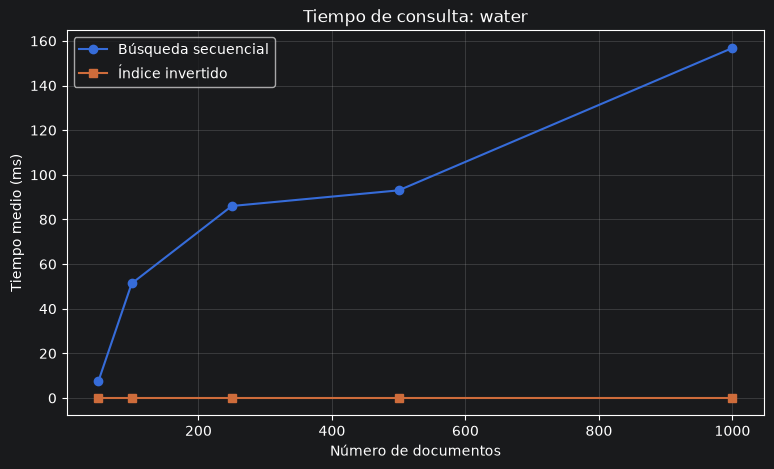

In [40]:
# C1 · La misma consulta «water» en los cinco tamaños; los tiempos ya se midieron en B3.
get_ipython().run_line_magic('matplotlib', 'inline')
datos_escalabilidad = [fila for fila in resultados_grandes if fila[2] == "water"]
assert [fila[0] for fila in datos_escalabilidad] == list(TAMANOS_CORPUS)
n_escalabilidad = np.array([fila[0] for fila in datos_escalabilidad], dtype=float)
tiempos_secuencial = np.array([fila[4] for fila in datos_escalabilidad], dtype=float)
tiempos_indice = np.array([fila[5] for fila in datos_escalabilidad], dtype=float)
print(formatear_tabla(["Documentos", "Tokens", "Secuencial (ms)", "Índice (ms)"],
                      [(fila[0], fila[1], formatear_ms(fila[4]), formatear_ms(fila[5])) for fila in datos_escalabilidad]))
fig, eje = plt.subplots(figsize=(9, 5))
eje.plot(n_escalabilidad, tiempos_secuencial, "o-", label="Búsqueda secuencial")
eje.plot(n_escalabilidad, tiempos_indice, "s-", label="Índice invertido")
eje.set(xlabel="Número de documentos", ylabel="Tiempo medio (ms)", title="Tiempo de consulta: water")
eje.grid(True, alpha=0.3)
eje.legend()
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

El ajuste describe solo estos cinco tamaños, esta consulta y este equipo; no demuestra por sí solo una complejidad asintótica. La búsqueda secuencial depende de los tokens recorridos y de la posición del término. Para un término, la consulta al índice es una búsqueda en el diccionario; las operaciones booleanas además dependen del tamaño de las listas de documentos. Construir el índice no se incluye en los tiempos de consulta.

Búsqueda secuencial: t(n) = 0.133321646 n + 28.2570938 ms; R² = 0.879044
  El ajuste tiene una capacidad descriptiva limitada de la variación observada (R² = 0.879).
Índice invertido: t(n) = 6.52183527e-07 n + 0.000211503593 ms; R² = 0.630163
  El ajuste tiene una capacidad descriptiva limitada de la variación observada (R² = 0.630).
El R² debe interpretarse junto con los residuos y con la variación entre ejecuciones; no valida extrapolaciones.


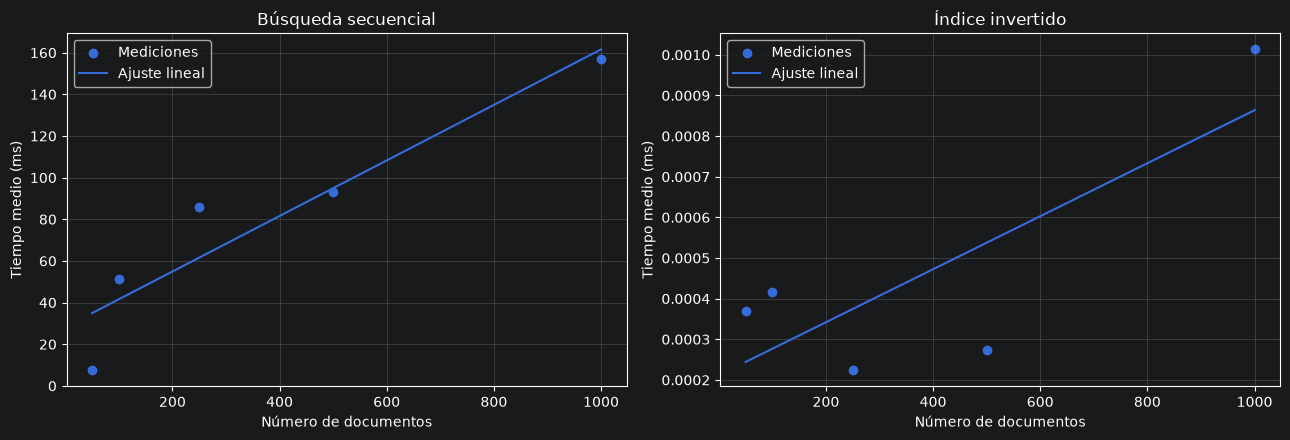

In [42]:
# C2 · Ajuste por mínimos cuadrados y R²; la función recibe solo datos en memoria.
def ajustar_linea(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or len(x) != len(y) or len(x) < 2 or len(np.unique(x)) < 2:
        raise ValueError("Se necesitan al menos dos tamaños distintos y una medición por tamaño.")
    pendiente, intercepto = np.polyfit(x, y, 1)
    estimados = pendiente * x + intercepto
    suma_total = np.sum((y - y.mean()) ** 2)
    r2 = None if suma_total == 0 else 1 - np.sum((y - estimados) ** 2) / suma_total
    return pendiente, intercepto, r2

a_prueba, b_prueba, r_prueba = ajustar_linea([1, 2, 3], [3, 5, 7])
assert np.isclose(a_prueba, 2) and np.isclose(b_prueba, 1) and np.isclose(r_prueba, 1)
assert ajustar_linea([1, 2, 3], [4, 4, 4])[2] is None

ajuste_seq = ajustar_linea(n_escalabilidad, tiempos_secuencial)
ajuste_idx = ajustar_linea(n_escalabilidad, tiempos_indice)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for eje, nombre, tiempos, (a, b, r2) in zip(ejes, ("Búsqueda secuencial", "Índice invertido"),
                                            (tiempos_secuencial, tiempos_indice), (ajuste_seq, ajuste_idx)):
    texto_r2 = "no definido (tiempos constantes)" if r2 is None else f"{r2:.6f}"
    print(f"{nombre}: t(n) = {a:.9g} n + {b:.9g} ms; R² = {texto_r2}")
    eje.scatter(n_escalabilidad, tiempos, label="Mediciones")
    eje.plot(n_escalabilidad, a * n_escalabilidad + b, label="Ajuste lineal")
    eje.set(xlabel="Número de documentos", ylabel="Tiempo medio (ms)", title=nombre)
    eje.grid(True, alpha=0.3)
    eje.legend()
    if r2 is not None:
        print(f"  El ajuste {'explica gran parte' if r2 >= 0.9 else 'tiene una capacidad descriptiva limitada'} de la variación observada (R² = {r2:.3f}).")
print("El R² debe interpretarse junto con los residuos y con la variación entre ejecuciones; no valida extrapolaciones.")
plt.tight_layout()
plt.show()